# Milestone 5

Continues the M3 notebook. Instead of adding onto the other notebook we've added to a copy.

In [1]:
import hashlib
import json
import platform
import random
import time
import urllib.request
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.linear_model import Ridge


In [2]:
# checking versions since numbers can change a bit between versions
# these are the versions colab had when we ran this (same as requirements.txt)
expected_versions = {'pandas': '2.2.3', 'numpy': '2.0.2', 'scikit-learn': '1.6.1'}
current_versions = {'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__}

for lib in expected_versions:
  if current_versions[lib] == expected_versions[lib]:
    print(lib, current_versions[lib], 'ok')
  else:
    print(lib, current_versions[lib], 'WARNING: expected', expected_versions[lib])
print('python', platform.python_version())

# setting the seed so anything random gives the same result every run
seed = 42
random.seed(seed)
np.random.seed(seed)

# folder for the tables and figures
results_folder = Path('results')
results_folder.mkdir(exist_ok=True)

pandas 2.2.3 ok
numpy 2.0.2 ok
scikit-learn 1.6.1 ok
python 3.13.18


In [3]:
# making sure the dataset on github is the exact same file we built the baseline on
# if someone changes the csv the numbers wont match anymore, so it stops here
data_url = 'https://raw.githubusercontent.com/tabishghouri/Machine-Learning-Project/main/Datasets/consommation-clients-evenements-pointe.csv'
expected_sha256 = '3cc2b88b8840671770f34cb20f94259c4de405a197b26a80b0f992d37e7d6370'

data_sha256 = hashlib.sha256(urllib.request.urlopen(data_url).read()).hexdigest()
assert data_sha256 == expected_sha256, 'dataset on github changed, numbers will not reproduce'
print('dataset checksum ok')

dataset checksum ok


In [4]:
# getting the m2 notebook from the commit we submitted for m2
# pinned to that commit so later edits to the m2 notebook cant change m3
m2_commit = '258a12e5aeb49db59b724599ae357c17a2db83dd'
m2_url = ('https://raw.githubusercontent.com/tabishghouri/Machine-Learning-Project/' + m2_commit +
          '/Milestone%202/Predicting_Quebec_Winter_Electricity_Demand_Machine_Learning_Project.ipynb')
urllib.request.urlretrieve(m2_url, 'm2_notebook.ipynb')
print('downloaded m2 notebook, commit', m2_commit[:7])

downloaded m2 notebook, commit 258a12e


In [5]:
%%capture m2_output
%run -i m2_notebook.ipynb

In [6]:
# same final check as the end of m2
print(hq.shape)
print(hq.isna().sum().sum(), 'blanks')
print(hq['was_missing'].sum(), 'rows added (missing hours)')
print(hq['spike_fixed'].sum(), 'values replaced (spikes)')
print(hq.duplicated(['substation', 'timestamp_clean']).sum(), 'duplicates')

plt.rcParams['figure.dpi'] = 110

(65661, 34)
0 blanks
1056 rows added (missing hours)
21 values replaced (spikes)
0 duplicates


# Feature Engineering

In [7]:
# Making Separate copy for ML model
model_df = hq.copy()

# Rows are ordered by substation and time
model_df = model_df.sort_values(['substation', 'timestamp_clean']).reset_index(drop=True)

# Creating lag features
model_df['lag_1h'] = model_df.groupby('substation')['energy_per_client'].shift(1)
model_df['lag_24h'] = model_df.groupby('substation')['energy_per_client'].shift(24)
model_df['lag_168h'] = model_df.groupby('substation')['energy_per_client'].shift(168)

display(model_df[[
    'substation', 'timestamp_clean',
    'energy_per_client', 'lag_1h',
    'lag_24h', 'lag_168h'
]].head(10))

,substation,timestamp_clean,energy_per_client,lag_1h,lag_24h,lag_168h
0,A,2022-01-01 00:00:00-05:00,3.584216,NaN,NaN,NaN
1,A,2022-01-01 01:00:00-05:00,3.477471,3.584216,NaN,NaN
2,A,2022-01-01 02:00:00-05:00,3.230708,3.477471,NaN,NaN
3,A,2022-01-01 03:00:00-05:00,3.077862,3.230708,NaN,NaN
4,A,2022-01-01 04:00:00-05:00,3.281740,3.077862,NaN,NaN
5,A,2022-01-01 05:00:00-05:00,3.965606,3.281740,NaN,NaN
6,A,2022-01-01 06:00:00-05:00,4.608892,3.965606,NaN,NaN
7,A,2022-01-01 07:00:00-05:00,4.589421,4.608892,NaN,NaN
8,A,2022-01-01 08:00:00-05:00,4.686603,4.589421,NaN,NaN
9,A,2022-01-01 09:00:00-05:00,5.253836,4.686603,NaN,NaN


In [8]:
#Hilo event features

#Hilo challenge active
model_df['is_hilo_event'] = (model_df['challenge_flag'] == 1).astype(int)

#pre/post challenge period
model_df['is_pre_post_event'] = (model_df['pre_post_challenge_flag'] == 1).astype(int)

#CPR challenge types
model_df['is_CPR'] = (model_df['challenge_type'] == 'CPR').astype(int)

#LCPR challenge type
model_df['is_LCPR'] = (model_df['challenge_type'] == 'LCPR').astype(int)

In [9]:
# mean of the whole day before, smoother than one hour from yesterday
model_df['lag_24h_mean_day'] = model_df.groupby('substation')['energy_per_client'].transform(lambda s: s.shift(24).rolling(24).mean())

# from figure 3 in m2, energy use is pretty flat above ~18 degrees and goes up in a straight-ish line below it
# a straight line on the raw temperature cant do that bend, so heating degrees = how far below 18 it is (0 when warmer)
model_df['heating_degrees'] = np.maximum(0, 18 - model_df['average_outside_temperature'])

# true/false and 0.0/1.0 into 1/0 for the models
model_df['weekend_holiday'] = model_df['weekend_holiday'].astype(int)
model_df['challenge_flag'] = model_df['challenge_flag'].astype(int)
model_df['pre_post_challenge_flag'] = model_df['pre_post_challenge_flag'].astype(int)

# dec, jan, feb so winter can be scored on its own
model_df['is_winter'] = model_df['month'].isin([12, 1, 2])

# get_dummies in the next cell replaces the substation column
# keeping a copy since the benchmarks and plots still need the letter
model_df['substation_name'] = model_df['substation']

In [10]:
#Converting substation labels into numeric values for linear regression
model_df = pd.get_dummies(model_df, columns=['substation'], prefix='station', dtype=int)

#Display
display(model_df[['station_A', 'station_B', 'station_C']].head())

,station_A,station_B,station_C
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


In [11]:
#Features
allFeatures = [
    'energy_per_client',
    'lag_1h',
    'lag_24h',
    'lag_168h',
    'hour_sin',
    'hour_cos',
    'month_sin',
    'month_cos',
    'average_outside_temperature',
    'average_temperature_setpoint',
    'average_inside_temperature',
    'average_relative_humidity',
    'average_snow_precipitation',
    'average_wind_speed',
    'is_hilo_event',
    'is_pre_post_event',
    'is_CPR',
    'is_LCPR',
    'station_A',
    'station_B',
    'station_C'
]
print(model_df.shape)

print(model_df[allFeatures].isna().sum())

(65661, 47)
energy_per_client                 0
lag_1h                            3
lag_24h                          72
lag_168h                        504
hour_sin                          0
hour_cos                          0
month_sin                         0
month_cos                         0
average_outside_temperature       0
average_temperature_setpoint      0
average_inside_temperature        0
average_relative_humidity         0
average_snow_precipitation        0
average_wind_speed                0
is_hilo_event                     0
is_pre_post_event                 0
is_CPR                            0
is_LCPR                           0
station_A                         0
station_B                         0
station_C                         0
dtype: int64


In [12]:
#Removing any rows that contain null, removing the first 168 of each substation
model_prepped_df = model_df.dropna( subset=['lag_1h', 'lag_24h', 'lag_168h']).copy()

print(model_prepped_df[allFeatures].isna().sum())

energy_per_client               0
lag_1h                          0
lag_24h                         0
lag_168h                        0
hour_sin                        0
hour_cos                        0
month_sin                       0
month_cos                       0
average_outside_temperature     0
average_temperature_setpoint    0
average_inside_temperature      0
average_relative_humidity       0
average_snow_precipitation      0
average_wind_speed              0
is_hilo_event                   0
is_pre_post_event               0
is_CPR                          0
is_LCPR                         0
station_A                       0
station_B                       0
station_C                       0
dtype: int64


# Train, Validation and Test Splits

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

In [14]:
#Using the processed dataframe
df = model_prepped_df.copy()

# Sort chronologically
df = df.sort_values('timestamp_clean')

#Define split dates using Montreal Time Zone

#changed the split to end at the end of 2022 as this was skewing the model carrying more weight on specifc parts of the year
train_end = pd.Timestamp('2023-01-01', tz='America/Montreal')

val_end = pd.Timestamp('2024-01-01', tz = 'America/Montreal')

#Split dataset
train_df = df[df['timestamp_clean'] < train_end].copy()

val_df = df[(df['timestamp_clean'] >= train_end) & (df['timestamp_clean'] < val_end)].copy()

test_df = df[df['timestamp_clean'] >= val_end].copy()

#Checking the number of rows
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))
print(len(train_df) + len(val_df) + len(test_df))

display(train_df.head())

Training rows: 25776
Validation rows: 26280
Testing rows: 13101
65157


,timestamp_clean,date,hour,timestamp_local,connected_clients,total_energy_consumed,average_temperature_setpoint,average_inside_temperature,connected_smart_tstats,average_solar_radiance,...,is_pre_post_event,is_CPR,is_LCPR,lag_24h_mean_day,heating_degrees,is_winter,substation_name,station_A,station_B,station_C
168,2022-01-08 00:00:00-05:00,2022-01-08,0,2022-01-08T00:00:00-05:00,19.0,86.293395,17.059384,17.735226,133.0,0.0,...,0,0,0,5.155398,33.1,True,A,1,0,0
43942,2022-01-08 00:00:00-05:00,2022-01-08,0,2022-01-08T00:00:00-05:00,40.0,237.403761,17.725368,18.289135,243.0,0.0,...,0,0,0,5.581600,33.1,True,C,0,0,1
22055,2022-01-08 00:00:00-05:00,2022-01-08,0,2022-01-08T00:00:00-05:00,9.0,62.712489,18.526677,19.627769,59.0,0.0,...,0,0,0,5.216420,33.1,True,B,0,1,0
169,2022-01-08 01:00:00-05:00,2022-01-08,1,2022-01-08T01:00:00-05:00,19.0,105.520490,17.134384,17.615403,133.0,0.0,...,0,0,0,5.173169,33.4,True,A,1,0,0
43943,2022-01-08 01:00:00-05:00,2022-01-08,1,2022-01-08T01:00:00-05:00,40.0,264.400827,18.032035,18.283375,243.0,0.0,...,0,0,0,5.582200,33.4,True,C,0,0,1


# Linear Regression (first model)

In [15]:
#Lag makes prediction better, see if we could do without it tho
features = [
    'hour_sin',
    'hour_cos',
    'day_of_week_cos',
    'day_of_week_sin',
    'average_outside_temperature',
    'average_relative_humidity',
    'average_snow_precipitation',
    'average_wind_speed',
    'station_A',
    'station_B'
]

target = 'energy_per_client'

X_train = train_df[features]
y_train = train_df[target]

X_val = val_df[features]
y_val =  val_df[target]

x_test = test_df[features]
y_test = test_df[target]

In [16]:
linear_model = Pipeline([
    ('scaler', StandardScaler()),
    ('regression', LinearRegression())
])

linear_model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()),
                ('regression', LinearRegression())])

In [17]:
y_pred = linear_model.predict(X_val)
comparison = pd.DataFrame({
    'Actual' : y_val.to_numpy(),
    'Predicted' : y_pred
})

display(comparison.head(10))

,Actual,Predicted
0,2.277030,3.381876
1,2.343862,3.320804
2,2.972443,3.755888
3,2.461517,3.087008
4,2.114161,3.148081
5,3.252515,3.522092
6,2.342811,2.851267
7,1.836685,2.912340
8,2.821635,3.286351
9,1.958270,2.874705


In [18]:
y_pred_test = linear_model.predict(x_test)

In [19]:
comparison2 = pd.DataFrame({
    'Actual' : y_test.to_numpy(),
    'Predicted' : y_pred_test
})

display(comparison2.head(10))

,Actual,Predicted
0,2.550371,5.137244
1,1.897350,4.702160
2,1.967196,4.763233
3,2.441067,4.905425
4,2.100347,4.470341
5,1.937011,4.531414
6,2.115965,4.354833
7,1.978314,4.415906
8,2.481529,4.789917
9,1.989311,4.423216


In [20]:
mae = mean_absolute_error(y_val, y_pred)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))

mape = mean_absolute_percentage_error(y_val, y_pred) * 100

print("mae:", mae)
print("rmse:", rmse)
print("mape:", mape)

mae: 1.0022900327001276
rmse: 1.3100443409560043
mape: 41.20778118454307


In [21]:
# testing measures for the same model on the test set (jan-jun 2024)
test_mae = mean_absolute_error(y_test, y_pred_test)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_mape = mean_absolute_percentage_error(y_test, y_pred_test) * 100

print('test mae:', test_mae)
print('test rmse:', test_rmse)
print('test mape:', test_mape)
print('test bias:', np.mean(y_pred_test - y_test))

# bias = average of (predicted - actual), so its guessing about 1.6 too high on every hour in 2024
# this model is trained on 2022 only, in the baseline table every model is retrained on 2022 + 2023 before testing

test mae: 1.7509373853229175
test rmse: 2.041852813272137
test mape: 99.86543415111873
test bias: 1.5804906311230893


# Scoring
Same scores for every model, MAE is the main one with kWh per client per hour. MAPE gets huge on summer hours where the actual value is small so we wont rank by it

In [22]:
# bias > 0 means the model guesses too high on average
def get_scores(actual, predicted):
  actual = np.asarray(actual, dtype=float)
  predicted = np.asarray(predicted, dtype=float)
  error = predicted - actual

  return {'MAE': np.mean(np.abs(error)),
          'RMSE': np.sqrt(np.mean(error ** 2)),
          'MAPE_%': 100 * np.mean(np.abs(error) / np.abs(actual)),
          'R2': 1 - np.sum(error ** 2) / np.sum((actual - actual.mean()) ** 2),
          'bias': np.mean(error),
          'n': len(actual)}

# scores on all hours, only winter hours, and only hilo event hours
def get_scores_by_slice(part_df, predicted):
  actual = part_df['energy_per_client'].to_numpy()
  predicted = np.asarray(predicted)
  slices = {'all': np.ones(len(part_df), dtype=bool),
            'winter': part_df['is_winter'].to_numpy(),
            'event': (part_df['challenge_flag'] == 1).to_numpy()}
  scores = {}
  for slice_name, mask in slices.items():
    if mask.sum() > 0:
      scores[slice_name] = get_scores(actual[mask], predicted[mask])
  return scores

pd.Series(get_scores(y_val, y_pred)).round(4)

MAE           1.0023
RMSE          1.3100
MAPE_%       41.2078
R2            0.4664
bias          0.0805
n         26280.0000
dtype: float64

# Naive Benchmarks

* N1 same hour yesterday
* N2 same hour last week
* N3 average for that substation, hour and weekend/holiday




In [23]:
# validation is scored with models trained on 2022
# test is scored with models retrained on 2022 + 2023 (thats how it would be used for real)
trainval_df = pd.concat([train_df, val_df])

val_predictions = {}
test_predictions = {}
test_predictions_trainonly = {}   # trained on 2022 only, used in the discrepancy analysis

# N1 and N2 dont need training, the lag columns already have the answer
val_predictions['N1 Seasonal naive, same hour yesterday'] = val_df['lag_24h'].to_numpy()
test_predictions['N1 Seasonal naive, same hour yesterday'] = test_df['lag_24h'].to_numpy()
test_predictions_trainonly['N1 Seasonal naive, same hour yesterday'] = test_df['lag_24h'].to_numpy()

val_predictions['N2 Seasonal naive, same hour last week'] = val_df['lag_168h'].to_numpy()
test_predictions['N2 Seasonal naive, same hour last week'] = test_df['lag_168h'].to_numpy()
test_predictions_trainonly['N2 Seasonal naive, same hour last week'] = test_df['lag_168h'].to_numpy()

In [24]:
# N3 climatology: average of the training data for each substation, hour and weekend/holiday
climatology_cols = ['substation_name', 'hour', 'weekend_holiday']

def climatology_predict(fit_df, predict_df):
  averages = fit_df.groupby(climatology_cols)['energy_per_client'].mean().rename('prediction').reset_index()
  merged = predict_df[climatology_cols].merge(averages, on=climatology_cols, how='left')
  # if a combo never showed up in training just use the overall average
  return merged['prediction'].fillna(fit_df['energy_per_client'].mean()).to_numpy()

val_predictions['N3 Climatology (substation x hour x weekend)'] = climatology_predict(train_df, val_df)
test_predictions['N3 Climatology (substation x hour x weekend)'] = climatology_predict(trainval_df, test_df)
test_predictions_trainonly['N3 Climatology (substation x hour x weekend)'] = climatology_predict(train_df, test_df)

for name in val_predictions:
  print(name, ' val mae:', round(get_scores(y_val, val_predictions[name])['MAE'], 3))

# same hour yesterday already gets 0.533 on validation, the first model got 1.002

N1 Seasonal naive, same hour yesterday  val mae: 0.533
N2 Seasonal naive, same hour last week  val mae: 0.792
N3 Climatology (substation x hour x weekend)  val mae: 1.379


# Course-level Baselines

Focus on linear aggression, kNN, and decision trees

We are gonna forecast tomorrow so a model can only use what we know the day before

In [25]:
features_day_ahead = [
    'lag_24h',
    'lag_168h',
    'lag_24h_mean_day',
    'hour_sin',
    'hour_cos',
    'day_of_week_sin',
    'day_of_week_cos',
    'month_sin',
    'month_cos',
    'weekend_holiday',
    'average_outside_temperature',
    'heating_degrees',
    'average_relative_humidity',
    'average_snow_precipitation',
    'average_wind_speed',
    'average_solar_radiance',
    'challenge_flag',
    'pre_post_challenge_flag',
    'station_A',
    'station_B'
]

In [26]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone

# picking k for kNN and max depth for the tree using validation mae
tuning = []

for k in [5, 10, 20, 40, 80, 160]:
  knn_model = Pipeline([
      ('scaler', StandardScaler()),
      ('knn', KNeighborsRegressor(n_neighbors=k, weights='distance'))
  ])
  knn_model.fit(train_df[features_day_ahead], train_df[target])
  mae_k = mean_absolute_error(y_val, knn_model.predict(val_df[features_day_ahead]))
  tuning.append({'model': 'kNN', 'param': 'k', 'value': k, 'val_MAE': mae_k})

for depth in [3, 5, 8, 10, 12, 15, 20]:
  tree_model = Pipeline([
      ('tree', DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=seed))
  ])
  tree_model.fit(train_df[features_day_ahead], train_df[target])
  mae_d = mean_absolute_error(y_val, tree_model.predict(val_df[features_day_ahead]))
  tuning.append({'model': 'Tree', 'param': 'max_depth', 'value': depth, 'val_MAE': mae_d})

tuning = pd.DataFrame(tuning)
tuning.to_csv(results_folder / 'tuning.csv', index=False)

best_k = int(tuning[tuning['model'] == 'kNN'].sort_values('val_MAE').iloc[0]['value'])
best_depth = int(tuning[tuning['model'] == 'Tree'].sort_values('val_MAE').iloc[0]['value'])
print('best k:', best_k)
print('best depth:', best_depth)

best k: 80
best depth: 8


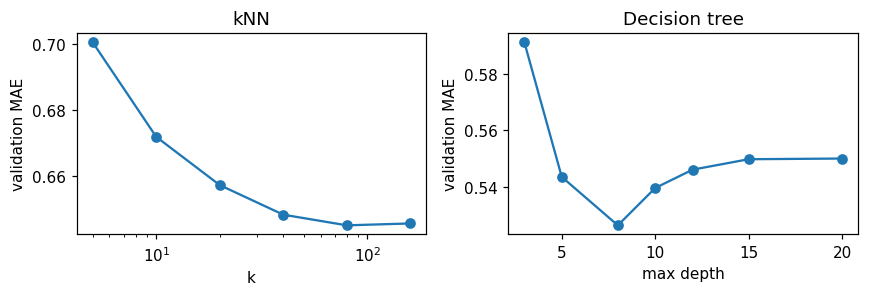

In [27]:
plt.figure(figsize=(8, 2.8))

plt.subplot(1, 2, 1)
knn_rows = tuning[tuning['model'] == 'kNN']
plt.plot(knn_rows['value'], knn_rows['val_MAE'], marker='o')
plt.xscale('log')
plt.xlabel('k')
plt.ylabel('validation MAE')
plt.title('kNN')

plt.subplot(1, 2, 2)
tree_rows = tuning[tuning['model'] == 'Tree']
plt.plot(tree_rows['value'], tree_rows['val_MAE'], marker='o')
plt.xlabel('max depth')
plt.ylabel('validation MAE')
plt.title('Decision tree')

plt.tight_layout()
plt.show()

# kNN keeps getting better until about k=80, the tree starts overfitting after depth 8

In [28]:
# C0 = the first linear regression from above (same features, same pipeline)
# C1-C3 use the day-ahead features
course_models = {
    'C0 Linear regression, team draft (no lags)': (linear_model, features),
    'C1 Linear regression, day-ahead features': (Pipeline([('scaler', StandardScaler()), ('regression', LinearRegression())]), features_day_ahead),
    f'C2 kNN, day-ahead features (k={best_k})': (Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=best_k, weights='distance'))]), features_day_ahead),
    f'C3 Decision tree, day-ahead features (depth={best_depth})': (Pipeline([('tree', DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=20, random_state=seed))]), features_day_ahead),
}

for name, (model, cols) in course_models.items():
  # validation: trained on 2022
  model_train = clone(model)
  model_train.fit(train_df[cols], train_df[target])
  val_predictions[name] = model_train.predict(val_df[cols])
  test_predictions_trainonly[name] = model_train.predict(test_df[cols])

  # test: retrained on 2022 + 2023
  model_trainval = clone(model)
  model_trainval.fit(trainval_df[cols], trainval_df[target])
  test_predictions[name] = model_trainval.predict(test_df[cols])

  print(name, ' val mae:', round(get_scores(y_val, val_predictions[name])['MAE'], 3))

C0 Linear regression, team draft (no lags)  val mae: 1.002
C1 Linear regression, day-ahead features  val mae: 0.506


C2 kNN, day-ahead features (k=80)  val mae: 0.645


C3 Decision tree, day-ahead features (depth=8)  val mae: 0.526


# Baseline Table
kWh per client per hour, lower is better. Winter is Dec to Feb and Event is hilo challenge hours

In [29]:
# every model, every split, every slice in one long table
rows = []
for name in val_predictions:
  for split_name, part_df, predictions in [('val', val_df, val_predictions),
                                           ('test', test_df, test_predictions),
                                           ('test_trainonly', test_df, test_predictions_trainonly)]:
    for slice_name, scores in get_scores_by_slice(part_df, predictions[name]).items():
      rows.append({'model': name, 'split': split_name, 'slice': slice_name, **scores})

results = pd.DataFrame(rows)
results.to_csv(results_folder / 'metrics_long.csv', index=False)

# making sure C0 matches the first model exactly
c0_val = results[results['model'].str.startswith('C0') & (results['split'] == 'val') & (results['slice'] == 'all')].iloc[0]
print('C0 val mae:', round(c0_val['MAE'], 4), ' first model val mae:', round(mae, 4))

C0 val mae: 1.0023  first model val mae: 1.0023


In [30]:
def pick(split_name, slice_name, cols):
  part = results[(results['split'] == split_name) & (results['slice'] == slice_name)].set_index('model')
  return part[cols]

# full table with every score, saved to results/ for the repo
baseline_table = pd.concat({
    'val': pick('val', 'all', ['MAE', 'RMSE', 'MAPE_%', 'R2']),
    'test': pick('test', 'all', ['MAE', 'RMSE', 'MAPE_%', 'R2']),
    'test winter': pick('test', 'winter', ['MAE', 'RMSE']),
    'test event hours': pick('test', 'event', ['MAE', 'bias']),
}, axis=1).round(3)
baseline_table.to_csv(results_folder / 'baseline_table.csv')

best_on_val = pick('val', 'all', ['MAE'])['MAE'].idxmin()
print('best on validation:', best_on_val)

# smaller table to read in the notebook: one header row, short names, just the main scores
short_names = {'N1': 'N1 same hour yesterday', 'N2': 'N2 same hour last week', 'N3': 'N3 average for that hour',
               'C0': 'C0 first LR (team draft)', 'C1': 'C1 LR with lags', 'C2': 'C2 kNN', 'C3': 'C3 decision tree'}

summary = pd.DataFrame({
    'val MAE (2023)': baseline_table[('val', 'MAE')],
    'test MAE (2024)': baseline_table[('test', 'MAE')],
    'test RMSE': baseline_table[('test', 'RMSE')],
    'test R2': baseline_table[('test', 'R2')],
    'winter MAE': baseline_table[('test winter', 'MAE')],
    'event MAE': baseline_table[('test event hours', 'MAE')],
    'event bias': baseline_table[('test event hours', 'bias')],
})
summary.index = [short_names[name[:2]] for name in summary.index]
summary.index.name = 'model'

# green + bold = best in that column (lowest error, highest R2), black text so its readable in dark mode
best = 'background-color: #d9ead3; color: black; font-weight: bold'
summary.style.format('{:.3f}') \
  .highlight_min(subset=['val MAE (2023)', 'test MAE (2024)', 'test RMSE', 'winter MAE', 'event MAE'], props=best) \
  .highlight_max(subset=['test R2'], props=best) \
  .set_table_styles([{'selector': 'th', 'props': 'text-align: center;'},
                     {'selector': 'th.row_heading', 'props': 'text-align: left;'}])

best on validation: C1 Linear regression, day-ahead features


,val MAE (2023),test MAE (2024),test RMSE,test R2,winter MAE,event MAE,event bias
model,,,,,,,
N1 same hour yesterday,0.533,0.368,0.579,0.683,0.609,0.998,0.785
N2 same hour last week,0.792,0.571,0.826,0.355,0.886,1.261,1.079
N3 average for that hour,1.379,1.372,1.574,-1.345,0.676,1.700,1.625
C0 first LR (team draft),1.002,1.568,1.800,-2.066,2.092,3.658,3.658
C1 LR with lags,0.506,0.402,0.531,0.733,0.606,0.801,-0.312
C2 kNN,0.645,0.597,0.798,0.397,0.926,1.301,1.292
C3 decision tree,0.526,0.466,0.757,0.458,0.863,1.422,1.300


C1 is our course-level baseline because its best on validation and on test it beats N1 on RMSE and event hours but not on overall MAE

In [31]:

# this is just a check, not part of our baseline
# lag_1h = the hour right before, so this is like predicting 7pm when you already know 6pm
# copying the hour before gets mae 0.236, way better than all our day-ahead models (best on test was 0.368)
# adding C1's other features barely helps (0.226), the model is basically just copying lag_1h
# but we forecast tomorrow, so we wont know the hour before when we make the forecast
# thats why lag_1h, indoor temp and setpoint stay out of the model, using them would be kind of cheating

next_hour = []

# persistence = guess the hour before
next_hour.append({'model': 'Persistence y(t-1)', **get_scores(y_test, test_df['lag_1h'])})

c1_next_hour = Pipeline([('scaler', StandardScaler()), ('regression', LinearRegression())])
c1_next_hour.fit(trainval_df[features_day_ahead + ['lag_1h']], trainval_df[target])
next_hour.append({'model': 'C1 + lag_1h', **get_scores(y_test, c1_next_hour.predict(test_df[features_day_ahead + ['lag_1h']]))})

next_hour = pd.DataFrame(next_hour).round(3)
next_hour.to_csv(results_folder / 'next_hour_sensitivity.csv', index=False)
next_hour

,model,MAE,RMSE,MAPE_%,R2,bias,n
0,Persistence y(t-1),0.236,0.413,12.773,0.839,0.000,13101
1,C1 + lag_1h,0.226,0.334,12.678,0.895,0.067,13101


In [32]:
# this checks what happens if we split randomly instead of by date
# random split: train on a random 80% of all hours (2022 to jun 2024) and test on the other 20%
# kNN goes from worst to best because the hours right next to each test hour are in training,
# so it just finds almost the same hour and copies it, basically memorizing and not predicting
# C0 gets better because it gets to see some 2024 hours in training, which it wouldnt have for a real forecast
# C1 gets worse because it has to fit hours from before and after the 29 nov 2023 drop together
# so a random split would make us pick kNN, which is actually the worst at predicting new months
# thats why we split by date: train on the past, test on the future

from sklearn.model_selection import train_test_split

# sorting first so the random split picks the same rows every run
all_rows = pd.concat([train_df, val_df, test_df]).sort_values(['timestamp_clean', 'substation_name'])
random_train, random_test = train_test_split(all_rows, test_size=0.2, random_state=seed)

random_vs_date = []
for name, (model, cols) in course_models.items():
  model_random = clone(model)
  model_random.fit(random_train[cols], random_train[target])
  random_mae = mean_absolute_error(random_test[target], model_random.predict(random_test[cols]))
  date_mae = get_scores(y_test, test_predictions[name])['MAE']
  random_vs_date.append({'model': name, 'test MAE, date split (Jan-Jun 2024)': date_mae, 'test MAE, random 80/20 split': random_mae})

random_vs_date = pd.DataFrame(random_vs_date).round(3)
random_vs_date.to_csv(results_folder / 'random_vs_date_split.csv', index=False)
random_vs_date

,model,"test MAE, date split (Jan-Jun 2024)","test MAE, random 80/20 split"
0,"C0 Linear regression, team draft (no lags)",1.568,1.030
1,"C1 Linear regression, day-ahead features",0.402,0.469
2,"C2 kNN, day-ahead features (k=80)",0.597,0.431
3,"C3 Decision tree, day-ahead features (depth=8)",0.466,0.436


# Discrepancy Analysis
C1 wins on validation (0.506 vs 0.533 for N1) but N1 wins on test MAE (0.368 vs 0.402) but why?

In [33]:
# comparing jan-jun of each year
model_df['year'] = model_df['timestamp_clean'].dt.year
jan_to_jun = model_df[model_df['month'].between(1, 6)]

by_year = jan_to_jun.groupby(['year', 'substation_name']).agg(
    mean_kwh_per_client=('energy_per_client', 'mean'),
    mean_clients=('connected_clients', 'mean'),
    mean_outside_temp=('average_outside_temperature', 'mean')).round(2)
by_year.index.names = ['year', 'substation']
by_year.to_csv(results_folder / 'discrepancy_jan_jun_by_year.csv')
by_year

# same number of clients in 2023 and 2024 and 2024 was only a bit warmer, but energy per client is about half

mean_kwh_per_client  mean_clients  mean_outside_temp
year substation                                                      
2022 A                          3.89         24.72               2.47
     B                          4.11         13.73               2.47
     C                          3.95         55.24               2.47
2023 A                          3.37         51.57               4.38
     B                          4.29         38.32               4.38
     C                          3.76         99.83               4.38
2024 A                          1.79         52.36               5.97
     B                          2.16         37.50               5.97
     C                          1.88        102.48               5.97

In [34]:
'''
want to find when the drop happened
for each day: actual energy / what the outdoor temperature alone says it should be
fitting a simple line (energy vs heating degrees) on oct 2022 to oct 2023
if the ratio is around 1 its a normal day for that weather
if all 3 substations drop on the same day its probably the data changing and not the weather
'''
daily_ratio = model_df.groupby(['substation_name', 'date']).agg(
    energy=('energy_per_client', 'mean'),
    temp=('average_outside_temperature', 'mean')).reset_index()
daily_ratio['date'] = pd.to_datetime(daily_ratio['date'])
daily_ratio['heating_degrees'] = np.maximum(0, 18 - daily_ratio['temp'])

fit_days = daily_ratio[(daily_ratio['date'] >= '2022-10-01') & (daily_ratio['date'] < '2023-11-01')]
x = np.column_stack([np.ones(len(fit_days)), fit_days['heating_degrees']])
intercept, slope = np.linalg.lstsq(x, fit_days['energy'], rcond=None)[0]

daily_ratio['ratio'] = daily_ratio['energy'] / (intercept + slope * daily_ratio['heating_degrees'])

# looking at the days around where it drops
around = daily_ratio[(daily_ratio['date'] >= '2023-11-24') & (daily_ratio['date'] <= '2023-12-03')]
around.pivot(index='date', columns='substation_name', values='ratio').round(2)

# all three drop to about 0.55-0.65 on nov 29 and stay there

substation_name,A,B,C
date,,,
2023-11-24,0.78,0.99,0.89
2023-11-25,0.93,1.22,1.03
2023-11-26,0.99,1.19,1.04
2023-11-27,0.91,1.08,1.01
2023-11-28,0.75,0.87,0.80
2023-11-29,0.54,0.63,0.56
2023-11-30,0.53,0.65,0.58
2023-12-01,0.49,0.60,0.54
2023-12-02,0.47,0.57,0.50


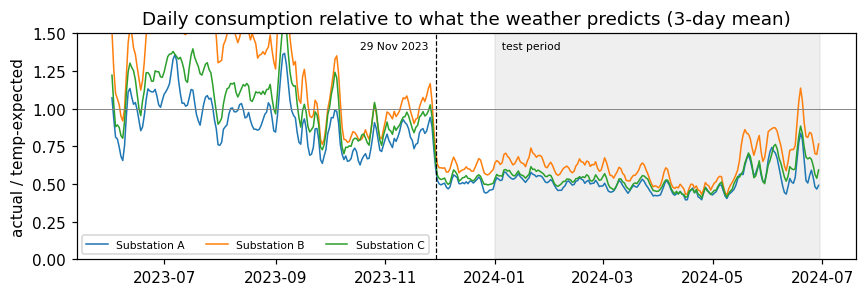

share of train + val rows after the drop: 4.6 %
share of test rows after the drop: 100 %


In [35]:
level_shift_date = '2023-11-29'
shown = daily_ratio[daily_ratio['date'] >= '2023-06-01']

plt.figure(figsize=(8, 2.8))
for station in ['A', 'B', 'C']:
  station_days = shown[shown['substation_name'] == station]
  plt.plot(station_days['date'], station_days['ratio'].rolling(3, center=True).mean(), linewidth=1, label=f'Substation {station}')

# dashed line = the drop, grey = test period
plt.axvline(pd.Timestamp(level_shift_date), color='black', linestyle='--', linewidth=0.8)
plt.axvspan(pd.Timestamp('2024-01-01'), shown['date'].max(), color='grey', alpha=0.12)
plt.axhline(1, color='grey', linewidth=0.6)
plt.text(pd.Timestamp('2024-01-01'), 1.45, '  test period', fontsize=7, va='top')
plt.text(pd.Timestamp(level_shift_date), 1.45, '29 Nov 2023  ', fontsize=7, va='top', ha='right')

plt.ylim(0, 1.5)
plt.ylabel('actual / temp-expected')
plt.title('Daily consumption relative to what the weather predicts (3-day mean)')
plt.legend(fontsize=7, ncol=3, loc='lower left')
plt.tight_layout()
plt.savefig(results_folder / 'fig_level_shift.png')
plt.show()

shift_time = pd.Timestamp(level_shift_date, tz='America/Montreal')
print('share of train + val rows after the drop:', round((trainval_df['timestamp_clean'] >= shift_time).mean() * 100, 1), '%')
print('share of test rows after the drop:', round((test_df['timestamp_clean'] >= shift_time).mean() * 100), '%')

# client and thermostat counts dont change that day, so probably a metering change, not people using less

In [36]:
# validation (2023) has hours before and after the drop, so can compare directly
n1 = 'N1 Seasonal naive, same hour yesterday'
c1 = 'C1 Linear regression, day-ahead features'
c0 = 'C0 Linear regression, team draft (no lags)'

before_after = []
for split_name, part_df, predictions in [('val', val_df, val_predictions), ('test', test_df, test_predictions)]:
  for period in ['before shift', 'after shift']:
    if period == 'before shift':
      mask = (part_df['timestamp_clean'] < shift_time).to_numpy()
    else:
      mask = (part_df['timestamp_clean'] >= shift_time).to_numpy()
    if mask.sum() == 0:
      continue
    for name in [n1, c1, c0]:
      scores = get_scores(part_df[target].to_numpy()[mask], predictions[name][mask])
      before_after.append({'split': split_name, 'period': period, 'model': name[:2],
                           'MAE': scores['MAE'], 'bias': scores['bias'], 'n': scores['n']})

before_after = pd.DataFrame(before_after).round(3)
before_after.to_csv(results_folder / 'discrepancy_before_after_shift.csv', index=False)
before_after


# before the drop C1 beats N1, after it C1 guesses too high
# C1 learned how much energy goes up when its cold from data before the drop
# N1 just copies yesterday so it adjusts right away
# the whole test set is after the drop so N1 wins on test mae
# models with no lags (C0, climatology) cant adjust at all, so C0 goes from 1.00 on val to 1.57 on test

,split,period,model,MAE,bias,n
0,val,before shift,N1,0.539,-0.002,23904
1,val,before shift,C1,0.474,-0.116,23904
2,val,before shift,C0,0.873,-0.140,23904
3,val,after shift,N1,0.475,0.035,2376
4,val,after shift,C1,0.821,0.800,2376
5,val,after shift,C0,2.303,2.303,2376
6,test,after shift,N1,0.368,0.010,13101
7,test,after shift,C1,0.402,0.220,13101
8,test,after shift,C0,1.568,1.471,13101


In [37]:
# where the errors are in the test set
errors = test_df[['timestamp_clean', 'hour', 'substation_name', 'challenge_flag', target]].copy()
errors['pred_C0'] = test_predictions[c0]
errors['pred_C1'] = test_predictions[c1]
errors['pred_N1'] = test_predictions[n1]
errors['abs_err_C0'] = (errors['pred_C0'] - errors[target]).abs()
errors['abs_err_C1'] = (errors['pred_C1'] - errors[target]).abs()
errors['abs_err_N1'] = (errors['pred_N1'] - errors[target]).abs()

by_month = errors.groupby(errors['timestamp_clean'].dt.month)[['abs_err_C0', 'abs_err_C1', 'abs_err_N1']].mean().round(3)
by_month.index.name = 'month (2024)'
by_month.to_csv(results_folder / 'discrepancy_mae_by_month_test.csv')
by_month

,abs_err_C0,abs_err_C1,abs_err_N1
month (2024),,,
1,2.063,0.588,0.534
2,2.122,0.625,0.689
3,1.919,0.381,0.377
4,1.750,0.304,0.280
5,0.904,0.281,0.173
6,0.665,0.238,0.167


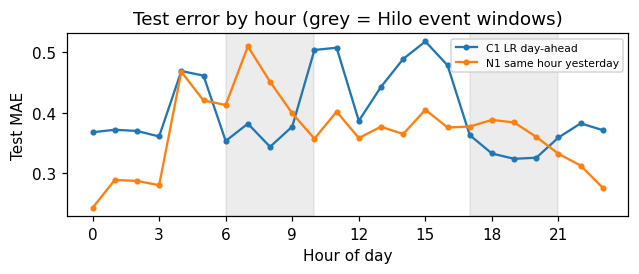

In [38]:
by_hour = errors.groupby('hour')[['abs_err_C1', 'abs_err_N1']].mean()

plt.figure(figsize=(6, 2.6))
plt.plot(by_hour.index, by_hour['abs_err_C1'], marker='o', markersize=3, label='C1 LR day-ahead')
plt.plot(by_hour.index, by_hour['abs_err_N1'], marker='o', markersize=3, label='N1 same hour yesterday')

# shading the hilo event windows like in m2
plt.axvspan(6, 10, alpha=0.15, color='gray')
plt.axvspan(17, 21, alpha=0.15, color='gray')

plt.xticks(range(0, 24, 3))
plt.xlabel('Hour of day')
plt.ylabel('Test MAE')
plt.title('Test error by hour (grey = Hilo event windows)')
plt.legend(fontsize=7)
plt.tight_layout()
plt.savefig(results_folder / 'fig_error_by_hour.png')
plt.show()

# N1 is worst in the morning event window (7-8am), C1 does better there and in the evening one
# C1 is worst from about 10am to 4pm

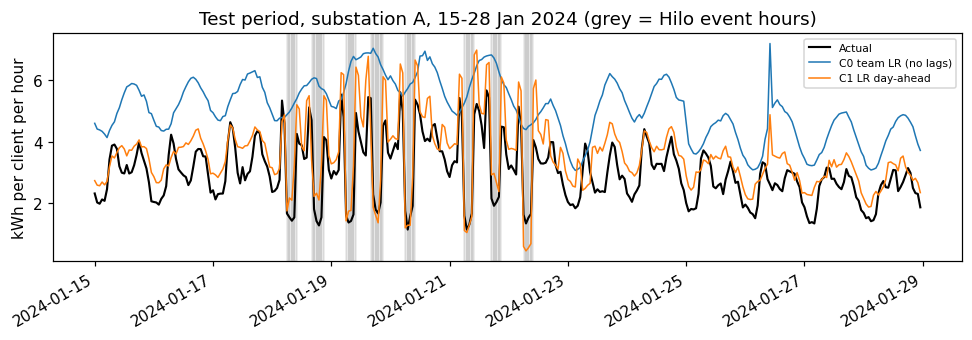

In [39]:
# two winter weeks of the test set, substation A
two_weeks = errors[(errors['substation_name'] == 'A') &
                   (errors['timestamp_clean'] >= pd.Timestamp('2024-01-15', tz='America/Montreal')) &
                   (errors['timestamp_clean'] < pd.Timestamp('2024-01-29', tz='America/Montreal'))]

plt.figure(figsize=(9, 3.2))
plt.plot(two_weeks['timestamp_clean'], two_weeks[target], color='black', linewidth=1.4, label='Actual')
plt.plot(two_weeks['timestamp_clean'], two_weeks['pred_C0'], linewidth=1, label='C0 team LR (no lags)')
plt.plot(two_weeks['timestamp_clean'], two_weeks['pred_C1'], linewidth=1, label='C1 LR day-ahead')

# grey = hilo event hours
for event_hour in two_weeks[two_weeks['challenge_flag'] == 1]['timestamp_clean']:
  plt.axvspan(event_hour, event_hour + pd.Timedelta(hours=1), color='grey', alpha=0.18)

plt.ylabel('kWh per client per hour')
plt.title('Test period, substation A, 15-28 Jan 2024 (grey = Hilo event hours)')
plt.legend(loc='upper right', fontsize=7)
plt.gcf().autofmt_xdate()
plt.tight_layout()
plt.savefig(results_folder / 'fig_test_two_weeks.png')
plt.show()

# C0 sits way above the actual line the whole time (no lags, still at the old level)
# C1 follows the level but the day after an event its 24h lag repeats yesterday's dip and rebound

In [40]:
log_lags = ['lag_24h', 'lag_168h', 'lag_24h_mean_day']

def log_features(part_df):
  x = part_df[features_day_ahead].copy()
  x[log_lags] = np.log(x[log_lags])
  return x

log_model = Pipeline([('scaler', StandardScaler()), ('regression', LinearRegression())])

# validation: trained on 2022
log_model.fit(log_features(train_df), np.log(train_df[target]))
log_val_scores = get_scores(y_val, np.exp(log_model.predict(log_features(val_df))))

# test: retrained on 2022 + 2023
log_model.fit(log_features(trainval_df), np.log(trainval_df[target]))
log_test_scores = get_scores(y_test, np.exp(log_model.predict(log_features(test_df))))

log_target = pd.DataFrame([{'split': 'val', **log_val_scores}, {'split': 'test', **log_test_scores}]).round(3)
log_target.to_csv(results_folder / 'diagnostic_log_target.csv', index=False)
log_target

# beats both C1 and N1 on val and test, so this is where m4 starts

,split,MAE,RMSE,MAPE_%,R2,bias,n
0,val,0.445,0.687,14.486,0.853,-0.119,26280
1,test,0.289,0.417,15.903,0.835,0.059,13101


#Improvements

In [41]:
model_df = model_df.sort_values(['substation_name', 'timestamp_clean'])
by_station = model_df.groupby('substation_name')

# event or pre/post hour = the usage that hour isnt normal
model_df['disturbed'] = ((model_df['challenge_flag'] == 1) | (model_df['pre_post_challenge_flag'] == 1)).astype(int)

# pre-heat vs rebound: is there an event in the next 3 hours?
event_soon = sum(by_station['challenge_flag'].shift(-k).fillna(0) for k in [1, 2, 3])
pre_post_only = (model_df['pre_post_challenge_flag'] == 1) & (model_df['challenge_flag'] == 0)
model_df['pre_heat'] = (pre_post_only & (event_soon > 0)).astype(int)
model_df['rebound'] = (pre_post_only & (event_soon == 0)).astype(int)

# was the hour the lag is copying disturbed
model_df['lag24_disturbed'] = by_station['disturbed'].shift(24).fillna(0).astype(int)
model_df['lag168_disturbed'] = by_station['disturbed'].shift(168).fillna(0).astype(int)

# clean lag: go back 1 day, then 2 days ... up to 7 until the hour wasnt disturbed
# if all 7 were disturbed (never happens in practice) just keep the normal lag_24h
model_df['lag_24h_clean'] = np.nan
for days_back in range(7, 0, -1):
  value = by_station['energy_per_client'].shift(24 * days_back)
  was_disturbed = by_station['disturbed'].shift(24 * days_back)
  model_df['lag_24h_clean'] = np.where(was_disturbed == 0, value, model_df['lag_24h_clean'])
model_df['lag_24h_clean'] = model_df['lag_24h_clean'].fillna(model_df['lag_24h'])

# interactions with how cold it is
model_df['event_x_hd'] = model_df['challenge_flag'] * model_df['heating_degrees']
model_df['preheat_x_hd'] = model_df['pre_heat'] * model_df['heating_degrees']

print('event hours:', model_df['challenge_flag'].sum(), ' pre-heat hours:', model_df['pre_heat'].sum(),
      ' rebound hours:', model_df['rebound'].sum())
print('rows where the 24h lag copied a disturbed hour:', model_df['lag24_disturbed'].sum())
print('rows where the clean lag is different from lag_24h:', (model_df['lag_24h_clean'] != model_df['lag_24h']).sum())

event hours: 717  pre-heat hours: 354  rebound hours: 354
rows where the 24h lag copied a disturbed hour: 1425
rows where the clean lag is different from lag_24h: 1497


In [42]:
# same rows as M3: drop the first week of each substation (no lag_168h yet)
df = model_df.dropna(subset=['lag_1h', 'lag_24h', 'lag_168h']).copy()
df = df.sort_values('timestamp_clean')

train_end = pd.Timestamp('2023-01-01', tz='America/Montreal')
val_end = pd.Timestamp('2024-01-01', tz='America/Montreal')

train_df = df[df['timestamp_clean'] < train_end].copy()
val_df = df[(df['timestamp_clean'] >= train_end) & (df['timestamp_clean'] < val_end)].copy()
test_df = df[df['timestamp_clean'] >= val_end].copy()
trainval_df = pd.concat([train_df, val_df])

target = 'energy_per_client'
print('train', len(train_df), ' val', len(val_df), ' test', len(test_df))   # should be 25776 / 26280 / 13101 like M3

# hilo event days per year, this matters a lot below
event_days = df[df['challenge_flag'] == 1].groupby(df['timestamp_clean'].dt.year)['date'].nunique()
print('event days per year:', event_days.to_dict())

train 25776  val 26280  test 13101
event days per year: {2022: 1, 2023: 23, 2024: 22}


## Evaluation Tools

In [43]:
def get_scores(actual, predicted):
  actual = np.asarray(actual, dtype=float)
  predicted = np.asarray(predicted, dtype=float)
  error = predicted - actual
  return {'MAE': np.mean(np.abs(error)),
          'RMSE': np.sqrt(np.mean(error ** 2)),
          'R2': 1 - np.sum(error ** 2) / np.sum((actual - actual.mean()) ** 2),
          'bias': np.mean(error),
          'n': len(actual)}

def get_scores_by_slice(part_df, predicted):
  actual = part_df[target].to_numpy()
  predicted = np.asarray(predicted)
  slices = {'all': np.ones(len(part_df), dtype=bool),
            'winter': part_df['is_winter'].to_numpy(),
            'event': (part_df['challenge_flag'] == 1).to_numpy(),
            'pre_heat': (part_df['pre_heat'] == 1).to_numpy()}
  return {name: get_scores(actual[mask], predicted[mask]) for name, mask in slices.items() if mask.sum() > 0}

In [44]:
def linear():
  return Pipeline([('scaler', StandardScaler()), ('regression', LinearRegression())])

def ridge(alpha):
  return Pipeline([('scaler', StandardScaler()), ('regression', Ridge(alpha=alpha))])

log_lag_cols = ['lag_24h', 'lag_168h', 'lag_24h_mean_day', 'lag_24h_clean']

def model_inputs(kind, cols, part_df):
  # returns the X table and the 'base' (log of yesterday's daily mean, only used by relative)
  x = part_df[cols].copy()
  base = np.log(part_df['lag_24h_mean_day'].to_numpy())
  if kind == 'log':
    for col in log_lag_cols:
      if col in cols:
        x[col] = np.log(x[col])
  if kind == 'relative':
    # trees cant predict outside the range they saw in training, so after the 29 nov drop they get stuck at the old level
    # predicting the ratio to yesterday's mean fixes that, the lags become log ratios to yesterday's mean too
    x = x.drop(columns='lag_24h_mean_day')
    for col in ['lag_24h', 'lag_168h', 'lag_24h_clean']:
      if col in x.columns:
        x[col] = np.log(x[col]) - base
  return x, base

def fit_model(model, fit_df):
  kind, cols, sk_model = model
  if kind == 'naive':
    return None
  x, base = model_inputs(kind, cols, fit_df)
  y = fit_df[target].to_numpy()
  if kind == 'log':
    y = np.log(y)
  if kind == 'relative':
    y = np.log(y) - base
  return clone(sk_model).fit(x, y)

def predict_model(model, fitted, part_df):
  kind, cols, sk_model = model
  if kind == 'naive':
    return part_df['lag_24h'].to_numpy()
  x, base = model_inputs(kind, cols, part_df)
  predicted = fitted.predict(x)
  if kind == 'log':
    predicted = np.exp(predicted)
  if kind == 'relative':
    predicted = np.exp(predicted + base)
  return predicted

def fit_and_score(model, fit_df, score_df):
  # fits on fit_df, returns (predictions on score_df, train MAE, fit seconds)
  start = time.perf_counter()
  fitted = fit_model(model, fit_df)
  fit_seconds = time.perf_counter() - start
  train_mae = get_scores(fit_df[target], predict_model(model, fitted, fit_df))['MAE']
  return predict_model(model, fitted, score_df), train_mae, fit_seconds

def validate(name, model):
  # M3 setup: fit on 2022, score on 2023
  predicted, train_mae, fit_seconds = fit_and_score(model, train_df, val_df)
  row = {'model': name, 'train MAE': train_mae, 'fit s': fit_seconds}
  for slice_name, scores in get_scores_by_slice(val_df, predicted).items():
    row[f'{slice_name} MAE'] = scores['MAE']
  row['bias'] = get_scores(val_df[target], predicted)['bias']
  return row

In [45]:
# rolling-origin folds over 2023, fit on everything before the month, forecast the month
fold_months = pd.period_range('2023-01', '2023-12', freq='M')
df_month = df['timestamp_clean'].dt.tz_localize(None).dt.to_period('M')
fold_df = df[df_month.between(fold_months[0], fold_months[-1])]
fold_month = df_month.loc[fold_df.index]

def rolling_folds(model):
  predicted = pd.Series(np.nan, index=fold_df.index)
  for month in fold_months:
    fit_rows = df[df_month < month]
    month_rows = fold_df[fold_month == month]
    fitted = fit_model(model, fit_rows)
    predicted.loc[month_rows.index] = predict_model(model, fitted, month_rows)
  return predicted.to_numpy()

def fold_summary(name, predicted):
  row = {'model': name}
  for slice_name, scores in get_scores_by_slice(fold_df, predicted).items():
    row[f'{slice_name} MAE'] = scores['MAE']
  monthly = pd.Series(np.abs(predicted - fold_df[target].to_numpy())).groupby(fold_month.to_numpy()).mean()
  row['_monthly'] = monthly
  return row

# day-block bootstrap: 95% interval for MAE(model) - MAE(reference)
# negative = model is better than the reference
def day_block_bootstrap(part_df, predicted, reference, n_boot=2000, seed=seed):
  actual = part_df[target].to_numpy()
  diff = np.abs(np.asarray(predicted) - actual) - np.abs(np.asarray(reference) - actual)
  days = pd.Series(diff).groupby(part_df['date'].astype(str).to_numpy())
  day_sum, day_count = days.sum().to_numpy(), days.size().to_numpy()

  rng = np.random.default_rng(seed)
  picks = rng.integers(0, len(day_sum), size=(n_boot, len(day_sum)))
  boot = day_sum[picks].sum(axis=1) / day_count[picks].sum(axis=1)
  return {'MAE diff': diff.mean(), 'CI low': np.percentile(boot, 2.5), 'CI high': np.percentile(boot, 97.5),
          'days': len(day_sum)}

### Part A: Log-Target model with Event-Aware Lags


In [46]:
# same 20 day-ahead features as M3's C1
features_day_ahead = ['lag_24h', 'lag_168h', 'lag_24h_mean_day', 'hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos',
                      'month_sin', 'month_cos', 'weekend_holiday', 'average_outside_temperature', 'heating_degrees',
                      'average_relative_humidity', 'average_snow_precipitation', 'average_wind_speed', 'average_solar_radiance',
                      'challenge_flag', 'pre_post_challenge_flag', 'station_A', 'station_B']

feature_sets = {
    'L1 (M3 log model)': features_day_ahead,
    '+ clean lag': features_day_ahead + ['lag_24h_clean'],
    '+ disturbed-lag flags': features_day_ahead + ['lag_24h_clean', 'lag24_disturbed', 'lag168_disturbed'],
    '+ pre-heat / rebound split': features_day_ahead + ['lag_24h_clean', 'lag24_disturbed', 'lag168_disturbed', 'pre_heat', 'rebound'],
    '+ event x heating degrees': features_day_ahead + ['lag_24h_clean', 'lag24_disturbed', 'lag168_disturbed', 'pre_heat', 'rebound',
                                                      'event_x_hd', 'preheat_x_hd'],
}

val_rows, fold_rows, fold_predictions = [], [], {}

# benchmarks first
for name, model in [('N1 same hour yesterday', ('naive', None, None)), ('C1 linear, raw kWh (M3)', ('raw', features_day_ahead, linear()))]:
  val_rows.append(validate(name, model))
  fold_predictions[name] = rolling_folds(model)
  fold_rows.append(fold_summary(name, fold_predictions[name]))

for name, cols in feature_sets.items():
  val_rows.append(validate(name, ('log', cols, linear())))
  fold_predictions[name] = rolling_folds(('log', cols, linear()))
  fold_rows.append(fold_summary(name, fold_predictions[name]))

def show(rows):
  table = pd.DataFrame(rows).set_index('model')
  table = table[[c for c in table.columns if not c.startswith('_')]]
  return table.round(3)

print('fit on 2022, scored on 2023 validation')
display(show(val_rows))
print('rolling folds, every month of 2023')
display(show(fold_rows))

fit on 2022, scored on 2023 validation


,train MAE,fit s,all MAE,winter MAE,event MAE,pre_heat MAE,bias
model,,,,,,,
N1 same hour yesterday,0.630,0.000,0.533,0.947,2.052,2.634,0.002
"C1 linear, raw kWh (M3)",0.555,0.018,0.506,0.805,1.446,1.846,-0.034
L1 (M3 log model),0.498,0.020,0.445,0.718,1.269,1.952,-0.119
+ clean lag,0.496,0.021,0.435,0.681,1.305,2.051,-0.126
+ disturbed-lag flags,0.496,0.022,0.434,0.675,1.317,1.982,-0.127
+ pre-heat / rebound split,0.495,0.023,0.438,0.690,1.299,1.822,-0.127
+ event x heating degrees,0.495,0.027,0.464,0.787,2.253,3.987,-0.126


rolling folds, every month of 2023


,all MAE,winter MAE,event MAE,pre_heat MAE
model,,,,
N1 same hour yesterday,0.533,0.947,2.052,2.634
"C1 linear, raw kWh (M3)",0.506,0.802,1.462,1.968
L1 (M3 log model),0.435,0.702,1.272,1.960
+ clean lag,0.425,0.670,1.302,2.152
+ disturbed-lag flags,0.423,0.661,1.312,2.069
+ pre-heat / rebound split,0.424,0.667,1.400,1.818
+ event x heating degrees,0.444,0.742,1.783,4.015


As we mentioned in M4 **Ridge** is one the improvements we wanted to try as tempature and heating degrees are strongly correlated

In [47]:
l2_cols = feature_sets['+ disturbed-lag flags']
l3_cols = feature_sets['+ event x heating degrees']

ridge_rows = []
for cols_name, cols in [('L2', l2_cols), ('L2 + all event features', l3_cols)]:
  for alpha in [0, 1, 10, 100, 1000, 3000]:
    predicted = rolling_folds(('log', cols, linear() if alpha == 0 else ridge(alpha)))
    row = fold_summary(f'{cols_name}, alpha={alpha}', predicted)
    ridge_rows.append(row)
    if cols_name == 'L2' and alpha == 1000:
      fold_predictions['Ridge L2 (alpha=1000)'] = predicted
display(show(ridge_rows))

# correlation that made us think about ridge
print('corr(outside temp, heating degrees):', round(df['average_outside_temperature'].corr(df['heating_degrees']), 3))
print('corr(log lag_24h, log lag_24h_clean):', round(np.log(df['lag_24h']).corr(np.log(df['lag_24h_clean'])), 3))

,all MAE,winter MAE,event MAE,pre_heat MAE
model,,,,
"L2, alpha=0",0.423,0.661,1.312,2.069
"L2, alpha=1",0.423,0.661,1.310,2.065
"L2, alpha=10",0.422,0.660,1.294,2.038
"L2, alpha=100",0.422,0.662,1.249,1.970
"L2, alpha=1000",0.430,0.679,1.233,2.024
"L2, alpha=3000",0.441,0.694,1.268,2.110
"L2 + all event features, alpha=0",0.444,0.742,1.783,4.015
"L2 + all event features, alpha=1",0.443,0.742,1.781,4.015
"L2 + all event features, alpha=10",0.443,0.741,1.764,4.004


corr(outside temp, heating degrees): -0.984
corr(log lag_24h, log lag_24h_clean): 0.99


# Milestone 5: Results

Everything below uses one protocol so the comparison is fair:
* **tuning / model choice:** the 12 rolling-origin folds over 2023 (fit on everything before the month, forecast the month)
* **final:** fit on 2022 + 2023 once, forecast Jan-Jun 2024 once, after every setting is frozen

Every run is written to `results/experiment_log.csv`.

In [48]:
# M5 setup: one protocol for every model, and every run goes into results/experiment_log.csv
#   tuning: the 12 rolling-origin folds over 2023 (fit on everything before the month, forecast that month)
#   final:  fit on 2022 + 2023 once, forecast jan-jun 2024 once, after every setting is frozen
# every model sees the same rows, the same day-ahead information, and the same scoring code
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.base import clone
import os

# fit_model / predict_model from above, plus the 3 naive benchmarks so they go through the same code
def fit_model(model, fit_df):
  kind, cols, sk_model = model
  if kind in ['naive', 'naive_week']:
    return None
  if kind == 'climatology':
    return fit_df.groupby(['substation_name', 'hour', 'weekend_holiday'])[target].mean().rename('prediction'), fit_df[target].mean()
  x, base = model_inputs(kind, cols, fit_df)
  y = fit_df[target].to_numpy()
  if kind == 'log':
    y = np.log(y)
  if kind == 'relative':
    y = np.log(y) - base
  return clone(sk_model).fit(x, y)

def predict_model(model, fitted, part_df):
  kind, cols, sk_model = model
  if kind == 'naive':
    return part_df['lag_24h'].to_numpy()
  if kind == 'naive_week':
    return part_df['lag_168h'].to_numpy()
  if kind == 'climatology':
    averages, overall = fitted
    keys = part_df[['substation_name', 'hour', 'weekend_holiday']]
    return keys.merge(averages.reset_index(), on=list(keys.columns), how='left')['prediction'].fillna(overall).to_numpy()
  x, base = model_inputs(kind, cols, part_df)
  predicted = fitted.predict(x)
  if kind == 'log':
    predicted = np.exp(predicted)
  if kind == 'relative':
    predicted = np.exp(predicted + base)
  return predicted

# same folds as above but also times the fitting
def rolling_folds(model):
  predicted = pd.Series(np.nan, index=fold_df.index)
  fit_seconds = 0
  for month in fold_months:
    fit_rows = df[df_month < month]
    month_rows = fold_df[fold_month == month]
    start = time.perf_counter()
    fitted = fit_model(model, fit_rows)
    fit_seconds += time.perf_counter() - start
    predicted.loc[month_rows.index] = predict_model(model, fitted, month_rows)
  return predicted.to_numpy(), fit_seconds

experiment_log = []

def log_run(stage, name, model, predicted, protocol='rolling folds 2023', params=None, fit_seconds=np.nan,
            run_seed=None, notes=''):
  # one row per run: what was fit, how, and every score we use
  kind, cols, sk_model = model
  part_df = fold_df if protocol == 'rolling folds 2023' else test_df
  row = {'run_id': len(experiment_log) + 1, 'stage': stage, 'model': name, 'target': kind,
         'n_features': 0 if cols is None else len(cols),
         'params': json.dumps(params if params is not None else {}),
         'protocol': protocol, 'seed': run_seed}
  for slice_name, scores in get_scores_by_slice(part_df, predicted).items():
    row[f'{slice_name}_MAE'] = scores['MAE']
  overall = get_scores(part_df[target], predicted)
  row['RMSE'], row['bias'] = overall['RMSE'], overall['bias']
  if protocol == 'rolling folds 2023':
    monthly = pd.Series(np.abs(predicted - fold_df[target].to_numpy())).groupby(fold_month.to_numpy()).mean()
    row['fold_MAE_std'] = monthly.std()
    row['worst_fold'] = str(monthly.idxmax())
  row['fit_s'] = fit_seconds
  row['notes'] = notes
  experiment_log.append(row)
  return row

def save_log():
  pd.DataFrame(experiment_log).round(4).to_csv(results_folder / 'experiment_log.csv', index=False)

l2_cols = feature_sets['+ disturbed-lag flags']
print(len(features_day_ahead), 'M3 day-ahead features,', len(l2_cols), 'M5 features (adds clean lag + 2 disturbed-lag flags)')
print('cores:', os.cpu_count(), ' python', platform.python_version(), ' sklearn', sklearn.__version__)


20 M3 day-ahead features, 23 M5 features (adds clean lag + 2 disturbed-lag flags)
cores: 2  python 3.13.18  sklearn 1.6.1


## 1. Tuning
Same rule for every model family: lowest overall fold MAE wins, ties (within 0.001) go to lower event-hour MAE. Grids were fixed before running.

In [49]:
# tuning: every family is tuned the same way, on the 12 rolling folds of 2023 (the test set is not touched)
# rule: lowest overall fold MAE wins; if two are within 0.001, the one with lower event-hour MAE wins
# grids were fixed before running. RF is small because each fit takes ~5-8 s on 2 cores
def knn(k):
  return Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(n_neighbors=k, weights='distance'))])

def tree(depth, run_seed=seed):
  return DecisionTreeRegressor(max_depth=depth, min_samples_leaf=20, random_state=run_seed)

def forest(depth, leaf, max_features, run_seed=seed, n_trees=100):
  return RandomForestRegressor(n_estimators=n_trees, max_depth=depth, min_samples_leaf=leaf, max_features=max_features,
                               n_jobs=-1, random_state=run_seed)

def boosting(rate, leaves, leaf, iters, run_seed=seed):
  # early stopping off: it would pick a random 10% of hours as validation, which leaks across time
  return HistGradientBoostingRegressor(learning_rate=rate, max_leaf_nodes=leaves, min_samples_leaf=leaf, max_iter=iters,
                                       early_stopping=False, random_state=run_seed)

search_spaces = {
  'C2 kNN (raw kWh, M3 features)': ('raw', features_day_ahead, [{'k': k} for k in [5, 10, 20, 40, 80, 160]],
                                     lambda p: knn(p['k'])),
  'C3 tree (raw kWh, M3 features)': ('raw', features_day_ahead, [{'max_depth': d} for d in [3, 5, 8, 10, 12, 15, 20]],
                                      lambda p: tree(p['max_depth'])),
  'R1 ridge (log, M5 features)': ('log', l2_cols, [{'alpha': a} for a in [0, 1, 10, 100, 1000, 3000]],
                                   lambda p: linear() if p['alpha'] == 0 else ridge(p['alpha'])),
  'T1 tree (ratio, M5 features)': ('relative', l2_cols, [{'max_depth': d} for d in [3, 5, 8, 10, 12, 15]],
                                    lambda p: tree(p['max_depth'])),
  'F1 random forest (ratio, M5 features)': ('relative', l2_cols,
      [{'max_depth': d, 'min_samples_leaf': l, 'max_features': f} for d in [10, None] for l in [10, 40] for f in [0.33, 0.66]],
      lambda p: forest(p['max_depth'], p['min_samples_leaf'], p['max_features'])),
  'G1 gradient boosting (ratio, M5 features)': ('relative', l2_cols,
      [{'learning_rate': r, 'max_leaf_nodes': n, 'min_samples_leaf': l, 'max_iter': i}
       for r in [0.03, 0.1] for n in [15, 31] for l in [20, 100] for i in [200, 500]],
      lambda p: boosting(p['learning_rate'], p['max_leaf_nodes'], p['min_samples_leaf'], p['max_iter'])),
}

best_params = {}
fold_predictions = {}
for family, (kind, cols, grid, build) in search_spaces.items():
  rows = []
  for params in grid:
    model = (kind, cols, build(params))
    predicted, fit_seconds = rolling_folds(model)
    row = log_run('tuning', family, model, predicted, params=params, fit_seconds=fit_seconds, run_seed=seed)
    rows.append((row['all_MAE'], row['event_MAE'], params, predicted))
  best_mae = min(r[0] for r in rows)
  close = [r for r in rows if r[0] <= best_mae + 0.001]
  chosen = min(close, key=lambda r: r[1])
  best_params[family] = chosen[2]
  fold_predictions[family] = chosen[3]
  print(f'{family}: best {chosen[2]}  fold MAE {chosen[0]:.3f}  event MAE {chosen[1]:.3f}')
  save_log()


C2 kNN (raw kWh, M3 features): best {'k': 40}  fold MAE 0.568  event MAE 1.797


C3 tree (raw kWh, M3 features): best {'max_depth': 8}  fold MAE 0.507  event MAE 2.365


R1 ridge (log, M5 features): best {'alpha': 100}  fold MAE 0.422  event MAE 1.249


T1 tree (ratio, M5 features): best {'max_depth': 8}  fold MAE 0.481  event MAE 1.914


F1 random forest (ratio, M5 features): best {'max_depth': None, 'min_samples_leaf': 10, 'max_features': 0.33}  fold MAE 0.431  event MAE 1.971


G1 gradient boosting (ratio, M5 features): best {'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 20, 'max_iter': 500}  fold MAE 0.414  event MAE 1.597


## 2. M3 to M5 progression (same folds)

In [50]:
# the path from M3 to M5 in the same log, so the progression table comes straight from experiment_log.csv
progression = [
  ('N1 same hour yesterday', ('naive', None, None)),
  ('N2 same hour last week', ('naive_week', None, None)),
  ('N3 climatology', ('climatology', None, None)),
  ('C1 linear (raw kWh, M3 features)', ('raw', features_day_ahead, linear())),
  ('L1 linear (log, M3 features)', ('log', features_day_ahead, linear())),
  ('L1 + clean lag', ('log', feature_sets['+ clean lag'], linear())),
  ('L2 = L1 + clean lag + disturbed-lag flags', ('log', l2_cols, linear())),
  ('L2 + pre-heat / rebound split', ('log', feature_sets['+ pre-heat / rebound split'], linear())),
  ('L2 + event x heating degrees', ('log', feature_sets['+ event x heating degrees'], linear())),
]
for name, model in progression:
  predicted, fit_seconds = rolling_folds(model)
  fold_predictions[name] = predicted
  log_run('progression', name, model, predicted, fit_seconds=fit_seconds, notes='M3 to M5 feature path')
save_log()

log_table = pd.DataFrame(experiment_log)
display(log_table[log_table['stage'] == 'progression'][['model', 'n_features', 'all_MAE', 'fold_MAE_std', 'winter_MAE', 'event_MAE', 'pre_heat_MAE']].round(3))


,model,n_features,all_MAE,fold_MAE_std,winter_MAE,event_MAE,pre_heat_MAE
49,N1 same hour yesterday,0,0.533,0.388,0.947,2.052,2.634
50,N2 same hour last week,0,0.792,0.603,1.509,1.947,3.908
51,N3 climatology,0,1.428,0.552,1.861,1.670,4.990
52,"C1 linear (raw kWh, M3 features)",20,0.506,0.216,0.802,1.462,1.968
53,"L1 linear (log, M3 features)",20,0.435,0.243,0.702,1.272,1.960
54,L1 + clean lag,21,0.425,0.228,0.670,1.302,2.152
55,L2 = L1 + clean lag + disturbed-lag flags,23,0.423,0.221,0.661,1.312,2.069
56,L2 + pre-heat / rebound split,25,0.424,0.225,0.667,1.400,1.818
57,L2 + event x heating degrees,27,0.444,0.283,0.742,1.783,4.015


## 3. Final test + uncertainty
One read of Jan-Jun 2024. Uncertainty three ways: spread of the 12 monthly fold MAEs, 5 seeds for the models with randomness, and a day-block bootstrap (2000 draws, whole days resampled) for test MAE and for the paired gain over N1.

In [51]:
# final models, settings frozen from the tuning above
final_models = {
  'N1 same hour yesterday': ('naive', None, None),
  'N2 same hour last week': ('naive_week', None, None),
  'N3 climatology': ('climatology', None, None),
  'C1 linear (raw kWh, M3)': ('raw', features_day_ahead, linear()),
  'C2 kNN (raw kWh, M3)': ('raw', features_day_ahead, knn(best_params['C2 kNN (raw kWh, M3 features)']['k'])),
  'C3 tree (raw kWh, M3)': ('raw', features_day_ahead, tree(best_params['C3 tree (raw kWh, M3 features)']['max_depth'])),
  'L1 linear (log, M3 features)': ('log', features_day_ahead, linear()),
  'L2 linear (log, M5 features)': ('log', l2_cols, linear()),
  'R1 ridge (log, M5 features)': ('log', l2_cols, ridge(best_params['R1 ridge (log, M5 features)']['alpha'])),
  'T1 tree (ratio, M5 features)': ('relative', l2_cols, tree(best_params['T1 tree (ratio, M5 features)']['max_depth'])),
  'F1 random forest (ratio, M5 features)': ('relative', l2_cols, forest(**{k if k != 'min_samples_leaf' else 'leaf': v for k, v in
      {'depth': best_params['F1 random forest (ratio, M5 features)']['max_depth'],
       'min_samples_leaf': best_params['F1 random forest (ratio, M5 features)']['min_samples_leaf'],
       'max_features': best_params['F1 random forest (ratio, M5 features)']['max_features']}.items()})),
  'G1 gradient boosting (ratio, M5 features)': ('relative', l2_cols, boosting(**{
      'rate': best_params['G1 gradient boosting (ratio, M5 features)']['learning_rate'],
      'leaves': best_params['G1 gradient boosting (ratio, M5 features)']['max_leaf_nodes'],
      'leaf': best_params['G1 gradient boosting (ratio, M5 features)']['min_samples_leaf'],
      'iters': best_params['G1 gradient boosting (ratio, M5 features)']['max_iter']})),
}
# rolling-fold predictions for the final list (same settings as tuning picked)
fold_name_map = {'C1 linear (raw kWh, M3)': 'C1 linear (raw kWh, M3 features)', 'C2 kNN (raw kWh, M3)': 'C2 kNN (raw kWh, M3 features)',
                 'C3 tree (raw kWh, M3)': 'C3 tree (raw kWh, M3 features)', 'L2 linear (log, M5 features)': 'L2 = L1 + clean lag + disturbed-lag flags'}
final_fold_predictions = {name: fold_predictions[fold_name_map.get(name, name)] for name in final_models}

# seeds: models with randomness are refit with 5 seeds on the final protocol
seeded = {'C3 tree (raw kWh, M3)', 'T1 tree (ratio, M5 features)', 'F1 random forest (ratio, M5 features)',
          'G1 gradient boosting (ratio, M5 features)'}
seeds = [seed, 0, 1, 2, 3]

test_predictions = {}
test_seed_mae = {}
timing = {}
for name, model in final_models.items():
  kind, cols, sk_model = model
  runs = []
  for run_seed in (seeds if name in seeded else [seed]):
    if sk_model is not None and 'random_state' in sk_model.get_params():
      model = (kind, cols, clone(sk_model).set_params(random_state=run_seed))
    start = time.perf_counter()
    fitted = fit_model(model, trainval_df)
    fit_seconds = time.perf_counter() - start
    start = time.perf_counter()
    predicted = predict_model(model, fitted, test_df)
    predict_ms = (time.perf_counter() - start) / len(test_df) * 1e6   # microseconds per hour forecast
    log_run('final test', name, model, predicted, protocol='fit 2022-2023, test Jan-Jun 2024', fit_seconds=fit_seconds,
            run_seed=run_seed, notes='settings frozen before this run')
    runs.append(predicted)
    if run_seed == seed:
      test_predictions[name] = predicted
      timing[name] = (fit_seconds, predict_ms)
  test_seed_mae[name] = [get_scores(test_df[target], p)['MAE'] for p in runs]
save_log()

# 95% interval for a model's own MAE, resampling whole days (hours inside a day are not independent)
def day_block_mae_ci(part_df, predicted, n_boot=2000, seed=seed):
  err = pd.Series(np.abs(np.asarray(predicted) - part_df[target].to_numpy())).groupby(part_df['date'].astype(str).to_numpy())
  day_sum, day_count = err.sum().to_numpy(), err.size().to_numpy()
  picks = np.random.default_rng(seed).integers(0, len(day_sum), size=(n_boot, len(day_sum)))
  boot = day_sum[picks].sum(axis=1) / day_count[picks].sum(axis=1)
  return np.percentile(boot, 2.5), np.percentile(boot, 97.5)

main_rows = []
for name in final_models:
  monthly = pd.Series(np.abs(final_fold_predictions[name] - fold_df[target].to_numpy())).groupby(fold_month.to_numpy()).mean()
  test = get_scores_by_slice(test_df, test_predictions[name])
  low, high = day_block_mae_ci(test_df, test_predictions[name])
  vs_n1 = day_block_bootstrap(test_df, test_predictions[name], test_predictions['N1 same hour yesterday'])
  main_rows.append({'model': name,
                    'fold MAE mean': monthly.mean(), 'fold MAE std': monthly.std(),
                    'test MAE': test['all']['MAE'], 'test MAE CI low': low, 'test MAE CI high': high,
                    'seed std': np.std(test_seed_mae[name]) if name in seeded else np.nan,
                    'test RMSE': test['all']['RMSE'], 'test R2': test['all']['R2'], 'test bias': test['all']['bias'],
                    'winter MAE': test['winter']['MAE'], 'event MAE': test['event']['MAE'], 'pre-heat MAE': test['pre_heat']['MAE'],
                    'diff vs N1': vs_n1['MAE diff'], 'diff vs N1 CI low': vs_n1['CI low'], 'diff vs N1 CI high': vs_n1['CI high'],
                    'fit s': timing[name][0], 'predict us/hour': timing[name][1]})
main_table = pd.DataFrame(main_rows).set_index('model')
main_table.round(4).to_csv(results_folder / 'main_table.csv')
display(main_table.round(3))


,fold MAE mean,fold MAE std,test MAE,test MAE CI low,test MAE CI high,seed std,test RMSE,test R2,test bias,winter MAE,event MAE,pre-heat MAE,diff vs N1,diff vs N1 CI low,diff vs N1 CI high,fit s,predict us/hour
model,,,,,,,,,,,,,,,,,
N1 same hour yesterday,0.540,0.388,0.368,0.328,0.413,NaN,0.579,0.683,0.010,0.609,0.998,1.202,0.000,0.000,0.000,0.000,0.009
N2 same hour last week,0.802,0.603,0.571,0.506,0.643,NaN,0.826,0.355,0.045,0.886,1.261,1.877,0.203,0.143,0.266,0.000,0.003
N3 climatology,1.436,0.552,1.372,1.276,1.470,NaN,1.574,-1.345,1.220,0.676,1.700,1.797,1.004,0.883,1.132,0.005,0.277
"C1 linear (raw kWh, M3)",0.509,0.216,0.402,0.374,0.433,NaN,0.531,0.733,0.220,0.606,0.801,0.946,0.034,0.000,0.066,0.038,0.346
"C2 kNN (raw kWh, M3)",0.572,0.288,0.580,0.534,0.634,NaN,0.792,0.406,0.518,0.916,1.143,2.141,0.212,0.173,0.251,0.018,100.474
"C3 tree (raw kWh, M3)",0.511,0.301,0.466,0.415,0.525,0.000,0.757,0.458,0.274,0.863,1.422,2.063,0.098,0.066,0.132,0.250,0.293
"L1 linear (log, M3 features)",0.439,0.243,0.289,0.264,0.317,NaN,0.417,0.835,0.059,0.463,0.534,0.907,-0.079,-0.102,-0.057,0.037,0.360
"L2 linear (log, M5 features)",0.427,0.221,0.276,0.253,0.300,NaN,0.390,0.856,0.065,0.423,0.508,0.983,-0.092,-0.121,-0.067,0.037,0.378
"R1 ridge (log, M5 features)",0.426,0.222,0.276,0.253,0.300,NaN,0.390,0.856,0.061,0.423,0.495,0.965,-0.092,-0.120,-0.067,0.044,0.338


### Do the top models actually separate?

In [52]:
# do the top models actually separate? paired day-block bootstrap on test + month-by-month on the folds
top = ['G1 gradient boosting (ratio, M5 features)', 'R1 ridge (log, M5 features)', 'L2 linear (log, M5 features)',
       'F1 random forest (ratio, M5 features)']
pairs = [(top[0], 'N1 same hour yesterday'), (top[0], top[1]), (top[0], top[3]), (top[1], top[2]), (top[3], top[1])]
separation = []
for a, b in pairs:
  on_test = day_block_bootstrap(test_df, test_predictions[a], test_predictions[b])
  month_a = pd.Series(np.abs(final_fold_predictions[a] - fold_df[target].to_numpy())).groupby(fold_month.to_numpy()).mean()
  month_b = pd.Series(np.abs(final_fold_predictions[b] - fold_df[target].to_numpy())).groupby(fold_month.to_numpy()).mean()
  on_val = day_block_bootstrap(fold_df, final_fold_predictions[a], final_fold_predictions[b])
  separation.append({'A': a.split(' (')[0], 'B': b.split(' (')[0],
                     'test MAE(A)-MAE(B)': on_test['MAE diff'], 'test CI low': on_test['CI low'], 'test CI high': on_test['CI high'],
                     'folds MAE(A)-MAE(B)': on_val['MAE diff'], 'folds CI low': on_val['CI low'], 'folds CI high': on_val['CI high'],
                     'months A better (of 12)': int((month_a < month_b).sum())})
separation = pd.DataFrame(separation)
separation.round(4).to_csv(results_folder / 'separation_top_models.csv', index=False)
display(separation.round(3))

# per-substation test MAE for the top models (one more check that the ranking is not one substation)
by_sub = pd.DataFrame({name.split(' (')[0]: pd.Series(np.abs(test_predictions[name] - test_df[target].to_numpy()))
                       .groupby(test_df['substation_name'].to_numpy()).mean() for name in ['N1 same hour yesterday'] + top})
by_sub.round(4).to_csv(results_folder / 'test_mae_by_substation.csv')
display(by_sub.round(3))


,A,B,test MAE(A)-MAE(B),test CI low,test CI high,folds MAE(A)-MAE(B),folds CI low,folds CI high,months A better (of 12)
0,G1 gradient boosting,N1 same hour yesterday,-0.108,-0.138,-0.082,-0.119,-0.152,-0.088,12
1,G1 gradient boosting,R1 ridge,-0.016,-0.030,-0.001,-0.008,-0.024,0.010,8
2,G1 gradient boosting,F1 random forest,-0.019,-0.028,-0.011,-0.017,-0.029,-0.007,7
3,R1 ridge,L2 linear,0.000,-0.001,0.001,-0.001,-0.005,0.002,7
4,F1 random forest,R1 ridge,0.003,-0.010,0.017,0.010,-0.008,0.030,8


,N1 same hour yesterday,G1 gradient boosting,R1 ridge,L2 linear,F1 random forest
A,0.365,0.258,0.276,0.276,0.278
B,0.396,0.283,0.297,0.297,0.302
C,0.343,0.238,0.253,0.253,0.256


### Main figure

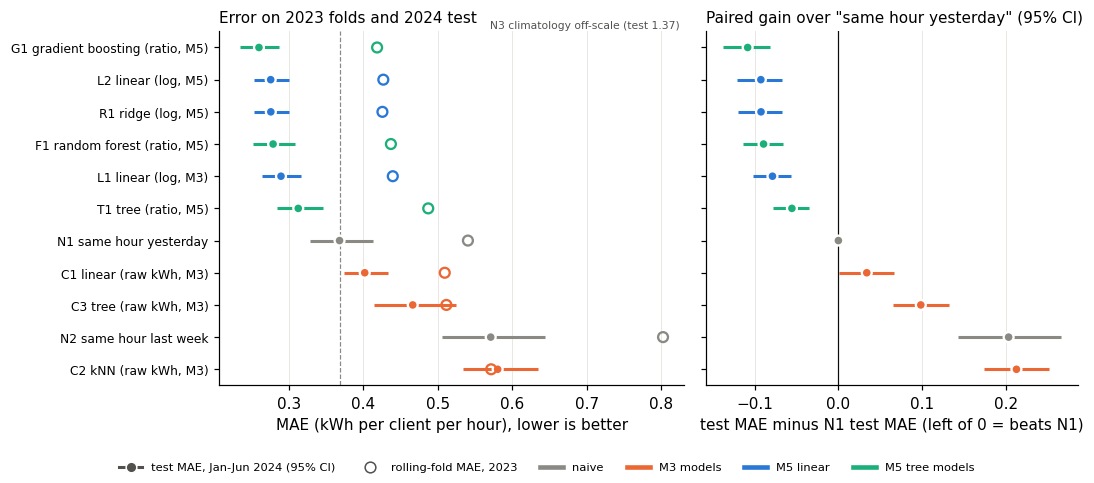

In [53]:
# main figure: test MAE with 95% day-block interval (left) and the paired gain over N1 (right)
# colours by group: grey = naive, orange = M3 models, blue = M5 linear, aqua = M5 tree models
group_colour = {'N': '#8a8984', 'C': '#eb6834', 'L': '#2a78d6', 'R': '#2a78d6', 'T': '#1baf7a', 'F': '#1baf7a', 'G': '#1baf7a'}
shown = main_table.drop(index='N3 climatology').sort_values('test MAE', ascending=False)
y = np.arange(len(shown))
colours = [group_colour[name[0]] for name in shown.index]
labels = [name.replace(' features)', ')') for name in shown.index]

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True, gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
ax.hlines(y, shown['test MAE CI low'], shown['test MAE CI high'], colors=colours, linewidth=2)
ax.scatter(shown['test MAE'], y, s=42, c=colours, zorder=3, edgecolors='white', linewidths=1.5, )
ax.scatter(shown['fold MAE mean'], y, s=42, facecolors='none', edgecolors=colours, linewidths=1.5, zorder=3)
ax.axvline(shown.loc['N1 same hour yesterday', 'test MAE'], color='#8a8984', linewidth=0.8, linestyle='--')
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=8)
ax.set_xlabel('MAE (kWh per client per hour), lower is better')
ax.set_title('Error on 2023 folds and 2024 test', fontsize=10, loc='left')
ax.text(0.99, 1.01, 'N3 climatology off-scale (test 1.37)', transform=ax.transAxes, fontsize=7, ha='right', color='#52514e')

ax = axes[1]
ax.hlines(y, shown['diff vs N1 CI low'], shown['diff vs N1 CI high'], colors=colours, linewidth=2)
ax.scatter(shown['diff vs N1'], y, s=42, c=colours, zorder=3, edgecolors='white', linewidths=1.5)
ax.axvline(0, color='#0b0b0b', linewidth=0.8)
ax.set_xlabel('test MAE minus N1 test MAE (left of 0 = beats N1)')
ax.set_title('Paired gain over "same hour yesterday" (95% CI)', fontsize=10, loc='left')

for ax in axes:
  ax.grid(axis='x', color='#e6e5e0', linewidth=0.6)
  ax.set_axisbelow(True)
  for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker='o', color='#52514e', markeredgecolor='white', linestyle='-', linewidth=2, markersize=7, label='test MAE, Jan-Jun 2024 (95% CI)'),
           Line2D([], [], marker='o', color='#52514e', markerfacecolor='none', linestyle='none', markersize=7, label='rolling-fold MAE, 2023'),
           Line2D([], [], color='#8a8984', linewidth=3, label='naive'),
           Line2D([], [], color='#eb6834', linewidth=3, label='M3 models'),
           Line2D([], [], color='#2a78d6', linewidth=3, label='M5 linear'),
           Line2D([], [], color='#1baf7a', linewidth=3, label='M5 tree models')]
fig.legend(handles=handles, loc='lower center', ncol=6, fontsize=7.5, frameon=False)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(results_folder / 'fig_main_results.png', dpi=160)
plt.show()


## 4. Error analysis (best model, G1)

In [54]:
# error analysis for the best model (G1) on the test set
best = 'G1 gradient boosting (ratio, M5 features)'
err = test_df[['timestamp_clean', 'date', 'hour', 'substation_name', 'challenge_flag', 'pre_heat', 'rebound',
               'lag24_disturbed', 'average_outside_temperature', 'heating_degrees', 'weekend_holiday', target]].copy()
err['predicted'] = test_predictions[best]
err['residual'] = err['predicted'] - err[target]          # > 0 = guessed too high
err['abs_err'] = err['residual'].abs()
err['abs_err_N1'] = np.abs(test_predictions['N1 same hour yesterday'] - err[target])
err['abs_err_R1'] = np.abs(test_predictions['R1 ridge (log, M5 features)'] - err[target])

# hour type: what is going on with Hilo at this hour
err['hour type'] = np.select([err['challenge_flag'] == 1, err['pre_heat'] == 1, err['rebound'] == 1, err['lag24_disturbed'] == 1],
                             ['event', 'pre-heat', 'rebound', 'day after (lag hit an event)'], 'normal')
by_type = err.groupby('hour type').agg(hours=('abs_err', 'size'), G1_MAE=('abs_err', 'mean'), G1_bias=('residual', 'mean'),
                                       R1_MAE=('abs_err_R1', 'mean'), N1_MAE=('abs_err_N1', 'mean'),
                                       share_of_total_error=('abs_err', 'sum'))
by_type['share_of_total_error'] = by_type['share_of_total_error'] / err['abs_err'].sum()
by_type = by_type.sort_values('G1_MAE', ascending=False)
by_type.round(4).to_csv(results_folder / 'error_by_hour_type.csv')
display(by_type.round(3))

# cold vs mild: error grows with how much heating there is
err['temp band'] = pd.cut(err['average_outside_temperature'], [-40, -20, -10, 0, 10, 40],
                          labels=['below -20', '-20 to -10', '-10 to 0', '0 to 10', 'above 10'])
by_temp = err.groupby('temp band', observed=True).agg(hours=('abs_err', 'size'), actual_mean=(target, 'mean'),
          G1_MAE=('abs_err', 'mean'), G1_bias=('residual', 'mean'), N1_MAE=('abs_err_N1', 'mean'))
by_temp['G1 MAE / actual'] = by_temp['G1_MAE'] / by_temp['actual_mean']
by_temp.round(4).to_csv(results_folder / 'error_by_temperature.csv')
display(by_temp.round(3))

by_month_best = err.groupby(err['timestamp_clean'].dt.month).agg(G1=('abs_err', 'mean'), R1=('abs_err_R1', 'mean'),
                                                                  N1=('abs_err_N1', 'mean'), bias_G1=('residual', 'mean'))
by_month_best.index.name = 'month (2024)'
by_month_best.round(4).to_csv(results_folder / 'error_by_month_best.csv')
display(by_month_best.round(3))

worst_days = err.groupby(['date', 'substation_name']).agg(G1_MAE=('abs_err', 'mean'), bias=('residual', 'mean'),
              mean_temp=('average_outside_temperature', 'mean'), event_hours=('challenge_flag', 'sum'),
              day_after_event=('lag24_disturbed', 'max')).sort_values('G1_MAE', ascending=False).head(10)
worst_days.round(3).to_csv(results_folder / 'worst_days_best_model.csv')
display(worst_days.round(3))
print('share of test days with an event:', round(err.groupby('date')['challenge_flag'].max().mean(), 3))
top10 = err.groupby(['date', 'substation_name'])['abs_err'].sum().sort_values(ascending=False)
print('top 5% of substation-days carry', round(top10.head(int(len(top10) * 0.05)).sum() / top10.sum() * 100, 1), '% of absolute error')


,hours,G1_MAE,G1_bias,R1_MAE,N1_MAE,share_of_total_error
hour type,,,,,,
pre-heat,174,0.969,-0.761,0.965,1.202,0.050
rebound,174,0.645,-0.237,0.737,0.745,0.033
event,357,0.469,0.185,0.495,0.998,0.049
day after (lag hit an event),366,0.431,-0.049,0.526,1.532,0.046
normal,12030,0.233,-0.054,0.245,0.296,0.822


,hours,actual_mean,G1_MAE,G1_bias,N1_MAE,G1 MAE / actual
temp band,,,,,,
-20 to -10,873,3.337,0.555,-0.307,0.821,0.166
-10 to 0,3333,2.870,0.370,-0.155,0.515,0.129
0 to 10,4203,1.830,0.244,-0.008,0.360,0.133
above 10,4692,1.129,0.141,0.009,0.186,0.125


,G1,R1,N1,bias_G1
month (2024),,,,
1,0.360,0.408,0.534,-0.022
2,0.412,0.438,0.689,-0.179
3,0.309,0.300,0.377,-0.101
4,0.210,0.211,0.280,-0.072
5,0.132,0.151,0.173,-0.013
6,0.141,0.151,0.167,0.025


G1_MAE   bias  mean_temp  event_hours  \
date       substation_name                                          
2024-02-29 B                 1.300 -1.300    -10.838            4   
           C                 1.174 -1.172    -10.838            4   
2024-02-24 B                 1.071 -0.507    -11.792            9   
           A                 1.059 -0.386    -11.792            9   
           C                 1.053 -0.385    -11.792            9   
2024-02-29 A                 1.034 -1.003    -10.838            4   
2024-03-01 B                 0.871 -0.865     -6.879            4   
2024-01-05 A                 0.870 -0.870     -8.671            0   
2024-02-18 B                 0.857 -0.513     -7.054            8   
           A                 0.844 -0.558     -7.054            8   

                            day_after_event  
date       substation_name                   
2024-02-29 B                              0  
           C                              0  
2024-02-24 B                              0  
           A                              0  
           C                              0  
2024-02-29 A                              0  
2024-03-01 B                              1  
2024-01-05 A                              0  
2024-02-18 B                              0  
           A                              0

share of test days with an event: 0.121
top 5% of substation-days carry 15.7 % of absolute error


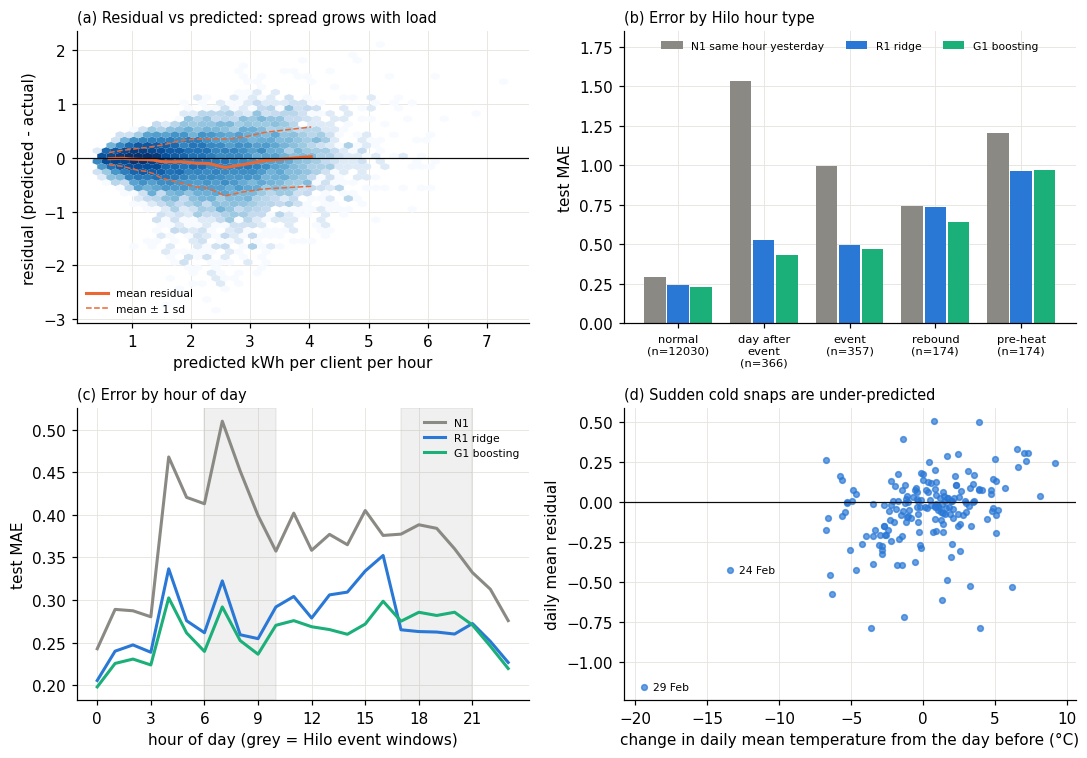

In [55]:
# error analysis figure for G1: residual vs predicted, error by hour type, by hour of day, and daily error vs temperature swing
daily = err.groupby('date').agg(temp=('average_outside_temperature', 'mean'), bias=('residual', 'mean'),
                                mae=('abs_err', 'mean'), events=('challenge_flag', 'max')).reset_index()
daily['temp_change'] = daily['temp'].diff()
daily.round(4).to_csv(results_folder / 'daily_error_best_model.csv', index=False)

grey, blue, orange, aqua = '#8a8984', '#2a78d6', '#eb6834', '#1baf7a'
fig, axes = plt.subplots(2, 2, figsize=(10, 7))

ax = axes[0, 0]
ax.hexbin(err['predicted'], err['residual'], gridsize=45, cmap='Blues', mincnt=1, bins='log', linewidths=0)
bins = pd.qcut(err['predicted'], 15)
binned = err.groupby(bins, observed=True).agg(x=('predicted', 'mean'), mean=('residual', 'mean'), sd=('residual', 'std'))
ax.plot(binned['x'], binned['mean'], color=orange, linewidth=2, label='mean residual')
ax.plot(binned['x'], binned['mean'] + binned['sd'], color=orange, linewidth=1, linestyle='--', label='mean ± 1 sd')
ax.plot(binned['x'], binned['mean'] - binned['sd'], color=orange, linewidth=1, linestyle='--')
ax.axhline(0, color='#0b0b0b', linewidth=0.8)
ax.set_xlabel('predicted kWh per client per hour')
ax.set_ylabel('residual (predicted - actual)')
ax.set_title('(a) Residual vs predicted: spread grows with load', fontsize=9.5, loc='left')
ax.legend(fontsize=7, frameon=False, loc='lower left')

ax = axes[0, 1]
order = ['normal', 'day after (lag hit an event)', 'event', 'rebound', 'pre-heat']
part = by_type.loc[order]
x = np.arange(len(order))
for offset, col, colour, label in [(-0.27, 'N1_MAE', grey, 'N1 same hour yesterday'), (0, 'R1_MAE', blue, 'R1 ridge'), (0.27, 'G1_MAE', aqua, 'G1 boosting')]:
  ax.bar(x + offset, part[col], width=0.25, color=colour, label=label)
ax.set_xticks(x)
ax.set_xticklabels([f'{name}\n(n={n})'.replace('day after (lag hit an event)', 'day after\nevent') for name, n in zip(order, part['hours'])], fontsize=7.5)
ax.set_ylabel('test MAE')
ax.set_title('(b) Error by Hilo hour type', fontsize=9.5, loc='left')
ax.set_ylim(0, 1.85)
ax.legend(fontsize=7, frameon=False, loc='upper center', ncol=3)

ax = axes[1, 0]
by_hour_best = err.groupby('hour')[['abs_err', 'abs_err_R1', 'abs_err_N1']].mean()
ax.axvspan(6, 10, alpha=0.12, color=grey)
ax.axvspan(17, 21, alpha=0.12, color=grey)
ax.plot(by_hour_best.index, by_hour_best['abs_err_N1'], color=grey, linewidth=2, label='N1')
ax.plot(by_hour_best.index, by_hour_best['abs_err_R1'], color=blue, linewidth=2, label='R1 ridge')
ax.plot(by_hour_best.index, by_hour_best['abs_err'], color=aqua, linewidth=2, label='G1 boosting')
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel('hour of day (grey = Hilo event windows)')
ax.set_ylabel('test MAE')
ax.set_title('(c) Error by hour of day', fontsize=9.5, loc='left')
ax.legend(fontsize=7, frameon=False, loc='upper right')

ax = axes[1, 1]
ax.scatter(daily['temp_change'], daily['bias'], s=14, color=blue, alpha=0.7)
for _, row in daily[daily['temp_change'] < -8].iterrows():
  ax.annotate(pd.Timestamp(row['date']).strftime('%d %b'), (row['temp_change'], row['bias']), fontsize=7,
              xytext=(6, -2), textcoords='offset points')
ax.axhline(0, color='#0b0b0b', linewidth=0.8)
ax.set_xlabel('change in daily mean temperature from the day before (°C)')
ax.set_ylabel('daily mean residual')
ax.set_title('(d) Sudden cold snaps are under-predicted', fontsize=9.5, loc='left')

for ax in axes.flat:
  ax.grid(color='#e6e5e0', linewidth=0.6)
  ax.set_axisbelow(True)
  for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(results_folder / 'fig_error_analysis.png', dpi=160)
plt.show()


## 5. Ablation, sensitivity and robustness

In [56]:
# ablation: take one group of inputs out of the two best models (G1, R1) and refit, same folds + same final test
# small fix to model_inputs so the ratio model still works when the lag columns are removed
def model_inputs(kind, cols, part_df):
  x = part_df[cols].copy()
  base = np.log(part_df['lag_24h_mean_day'].to_numpy())
  if kind == 'log':
    for col in log_lag_cols:
      if col in cols:
        x[col] = np.log(x[col])
  if kind == 'relative':
    x = x.drop(columns='lag_24h_mean_day', errors='ignore')
    for col in ['lag_24h', 'lag_168h', 'lag_24h_clean']:
      if col in x.columns:
        x[col] = np.log(x[col]) - base
  return x, base

groups = {
  'all lags (24h, 168h, day mean, clean)': ['lag_24h', 'lag_168h', 'lag_24h_mean_day', 'lag_24h_clean'],
  'event-aware lag features (clean lag + 2 flags)': ['lag_24h_clean', 'lag24_disturbed', 'lag168_disturbed'],
  'weather (6 columns incl. heating degrees)': ['average_outside_temperature', 'heating_degrees', 'average_relative_humidity',
                                                'average_snow_precipitation', 'average_wind_speed', 'average_solar_radiance'],
  'temperature only (outside temp + heating degrees)': ['average_outside_temperature', 'heating_degrees'],
  'Hilo event flags (event + pre/post)': ['challenge_flag', 'pre_post_challenge_flag'],
  'calendar (hour, weekday, month, weekend/holiday)': ['hour_sin', 'hour_cos', 'day_of_week_sin', 'day_of_week_cos',
                                                       'month_sin', 'month_cos', 'weekend_holiday'],
  'substation dummies': ['station_A', 'station_B'],
}
ablation_bases = {'G1 gradient boosting (ratio, M5 features)': final_models['G1 gradient boosting (ratio, M5 features)'],
                  'R1 ridge (log, M5 features)': final_models['R1 ridge (log, M5 features)']}

def fold_and_test(name, model, stage, notes):
  predicted, fit_seconds = rolling_folds(model)
  fold_row = log_run(stage, name, model, predicted, fit_seconds=fit_seconds, run_seed=seed, notes=notes)
  fitted = fit_model(model, trainval_df)
  test_pred = predict_model(model, fitted, test_df)
  test_row = log_run(stage, name, model, test_pred, protocol='fit 2022-2023, test Jan-Jun 2024', run_seed=seed, notes=notes)
  return fold_row, test_row

ablation_rows = []
for base_name, (kind, cols, sk_model) in ablation_bases.items():
  short = base_name.split(' (')[0]
  ablation_rows.append({'model': short, 'removed': 'nothing (full model)',
                        'fold MAE': get_scores(fold_df[target], final_fold_predictions[base_name])['MAE'], 'test MAE': main_table.loc[base_name, 'test MAE'],
                        'test event MAE': main_table.loc[base_name, 'event MAE']})
  for group, drop in groups.items():
    kept = [c for c in cols if c not in drop]
    fold_row, test_row = fold_and_test(f'{short} minus {group}', (kind, kept, sk_model), 'ablation', f'removed: {group}')
    monthly_mean = fold_row['all_MAE']
    ablation_rows.append({'model': short, 'removed': group, 'fold MAE': monthly_mean, 'test MAE': test_row['all_MAE'],
                          'test event MAE': test_row['event_MAE']})

# target ablation: same boosting settings and features, only the target changes
g1_kind, g1_cols, g1_model = final_models['G1 gradient boosting (ratio, M5 features)']
for kind, label in [('raw', 'target = raw kWh (instead of ratio)'), ('log', 'target = log kWh (instead of ratio)')]:
  fold_row, test_row = fold_and_test(f'G1 with {label}', (kind, g1_cols, g1_model), 'ablation', label)
  ablation_rows.append({'model': 'G1 gradient boosting', 'removed': label, 'fold MAE': fold_row['all_MAE'],
                        'test MAE': test_row['all_MAE'], 'test event MAE': test_row['event_MAE']})
save_log()

ablation = pd.DataFrame(ablation_rows)
full = ablation[ablation['removed'] == 'nothing (full model)'].set_index('model')
ablation['test MAE change'] = ablation['test MAE'] - ablation['model'].map(full['test MAE'])
ablation['fold MAE change'] = ablation['fold MAE'] - ablation['model'].map(full['fold MAE'])
ablation.round(4).to_csv(results_folder / 'ablation.csv', index=False)
display(ablation.round(3))


,model,removed,fold MAE,test MAE,test event MAE,test MAE change,fold MAE change
0,G1 gradient boosting,nothing (full model),0.414,0.260,0.469,0.000,0.000
1,G1 gradient boosting,"all lags (24h, 168h, day mean, clean)",0.476,0.278,0.494,0.019,0.062
2,G1 gradient boosting,event-aware lag features (clean lag + 2 flags),0.418,0.267,0.504,0.007,0.004
3,G1 gradient boosting,weather (6 columns incl. heating degrees),0.462,0.297,0.473,0.037,0.048
4,G1 gradient boosting,temperature only (outside temp + heating degrees),0.450,0.291,0.456,0.032,0.036
5,G1 gradient boosting,Hilo event flags (event + pre/post),0.438,0.297,1.195,0.037,0.024
6,G1 gradient boosting,"calendar (hour, weekday, month, weekend/holiday)",0.442,0.290,0.586,0.030,0.028
7,G1 gradient boosting,substation dummies,0.416,0.261,0.485,0.001,0.002
8,R1 ridge,nothing (full model),0.422,0.276,0.495,0.000,0.000
9,R1 ridge,"all lags (24h, 168h, day mean, clean)",0.879,1.191,1.087,0.915,0.457


In [57]:
# sensitivity: G1's best setting sat on the edge of the grid (smallest rate, fewest leaves, most iterations)
# so we push past the edge on the folds only (test is not used for this)
g1_best = best_params['G1 gradient boosting (ratio, M5 features)']
sensitivity_rows = []
for iters in [100, 200, 500, 1000, 2000]:
  model = ('relative', l2_cols, boosting(g1_best['learning_rate'], g1_best['max_leaf_nodes'], g1_best['min_samples_leaf'], iters))
  predicted, fit_seconds = rolling_folds(model)
  row = log_run('sensitivity', 'G1 gradient boosting (ratio, M5 features)', model, predicted, fit_seconds=fit_seconds, run_seed=seed,
                params={**g1_best, 'max_iter': iters}, notes='vary number of boosting rounds')
  sensitivity_rows.append({'setting': 'max_iter', 'value': iters, 'fold MAE': row['all_MAE'], 'event MAE': row['event_MAE']})
for leaves in [4, 7, 15, 31]:
  model = ('relative', l2_cols, boosting(g1_best['learning_rate'], leaves, g1_best['min_samples_leaf'], g1_best['max_iter']))
  predicted, fit_seconds = rolling_folds(model)
  row = log_run('sensitivity', 'G1 gradient boosting (ratio, M5 features)', model, predicted, fit_seconds=fit_seconds, run_seed=seed,
                params={**g1_best, 'max_leaf_nodes': leaves}, notes='vary tree size')
  sensitivity_rows.append({'setting': 'max_leaf_nodes', 'value': leaves, 'fold MAE': row['all_MAE'], 'event MAE': row['event_MAE']})
ridge_sens = pd.DataFrame(experiment_log)
ridge_sens = ridge_sens[(ridge_sens['stage'] == 'tuning') & (ridge_sens['model'] == 'R1 ridge (log, M5 features)')]
for _, r in ridge_sens.iterrows():
  sensitivity_rows.append({'setting': 'ridge alpha', 'value': json.loads(r['params'])['alpha'], 'fold MAE': r['all_MAE'], 'event MAE': r['event_MAE']})
sensitivity = pd.DataFrame(sensitivity_rows)
sensitivity.round(4).to_csv(results_folder / 'sensitivity_hyperparameters.csv', index=False)
save_log()
display(sensitivity.round(3))

# robustness: our weather columns are the observed weather, a real forecast would not be perfect
# add random error to the outside temperature on the test inputs (heating degrees recomputed from it), 5 draws per level
# plus a fixed 2 C warm / cold bias. models are not refit, only their inputs change. N1 does not use weather
def noisy_test(sd=0.0, shift=0.0, draw=0):
  noisy = test_df.copy()
  noise = np.random.default_rng(1000 + draw).normal(0, sd, len(noisy)) if sd > 0 else 0
  noisy['average_outside_temperature'] = noisy['average_outside_temperature'] + noise + shift
  noisy['heating_degrees'] = np.maximum(0, 18 - noisy['average_outside_temperature'])
  return noisy

fitted_final = {name: fit_model(final_models[name], trainval_df) for name in ['G1 gradient boosting (ratio, M5 features)', 'R1 ridge (log, M5 features)']}
robust_rows = []
scenarios = [('none', 0, 0)] + [(f'random error, sd {sd} C', sd, 0) for sd in [1, 2, 3, 5]] + [('forecast 2 C too warm', 0, 2), ('forecast 2 C too cold', 0, -2)]
for label, sd, shift in scenarios:
  for name, fitted in fitted_final.items():
    maes = [get_scores(test_df[target], predict_model(final_models[name], fitted, noisy_test(sd, shift, d)))['MAE']
            for d in (range(5) if sd > 0 else [0])]
    robust_rows.append({'scenario': label, 'temp error sd': sd, 'temp shift': shift, 'model': name.split(' (')[0],
                        'test MAE': np.mean(maes), 'std over draws': np.std(maes)})
  robust_rows.append({'scenario': label, 'temp error sd': sd, 'temp shift': shift, 'model': 'N1 same hour yesterday',
                      'test MAE': main_table.loc['N1 same hour yesterday', 'test MAE'], 'std over draws': 0})
robustness = pd.DataFrame(robust_rows)
robustness.round(4).to_csv(results_folder / 'robustness_weather_error.csv', index=False)
display(robustness.pivot(index='scenario', columns='model', values='test MAE').loc[[s[0] for s in scenarios]].round(3))


,setting,value,fold MAE,event MAE
0,max_iter,100,0.441,1.698
1,max_iter,200,0.420,1.542
2,max_iter,500,0.414,1.597
3,max_iter,1000,0.418,1.648
4,max_iter,2000,0.424,1.668
5,max_leaf_nodes,4,0.429,1.347
6,max_leaf_nodes,7,0.419,1.457
7,max_leaf_nodes,15,0.414,1.597
8,max_leaf_nodes,31,0.420,1.568
9,ridge alpha,0,0.423,1.312


model,G1 gradient boosting,N1 same hour yesterday,R1 ridge
scenario,,,
none,0.260,0.368,0.276
"random error, sd 1 C",0.260,0.368,0.277
"random error, sd 2 C",0.264,0.368,0.281
"random error, sd 3 C",0.268,0.368,0.287
"random error, sd 5 C",0.281,0.368,0.304
forecast 2 C too warm,0.270,0.368,0.267
forecast 2 C too cold,0.258,0.368,0.294


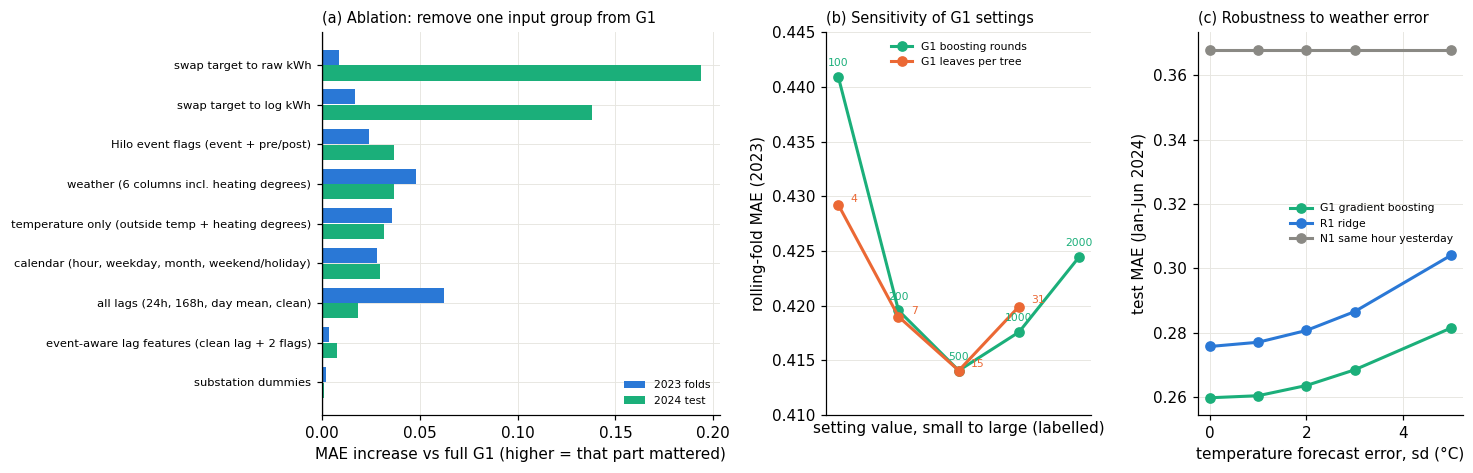

In [58]:
# one figure for section 5: ablation (G1), hyperparameter sensitivity, and forecast-weather robustness
grey, blue, orange, aqua = '#8a8984', '#2a78d6', '#eb6834', '#1baf7a'
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.4), gridspec_kw={'width_ratios': [1.5, 1, 1]})

ax = axes[0]
g1_abl = ablation[(ablation['model'] == 'G1 gradient boosting') & (ablation['removed'] != 'nothing (full model)')]
g1_abl = g1_abl.sort_values('test MAE change')
y = np.arange(len(g1_abl))
ax.barh(y + 0.2, g1_abl['fold MAE change'], height=0.38, color=blue, label='2023 folds')
ax.barh(y - 0.2, g1_abl['test MAE change'], height=0.38, color=aqua, label='2024 test')
ax.set_yticks(y)
ax.set_yticklabels([r.replace(' (instead of ratio)', '').replace('target = ', 'swap target to ') for r in g1_abl['removed']], fontsize=7.5)
ax.axvline(0, color='#0b0b0b', linewidth=0.8)
ax.set_xlabel('MAE increase vs full G1 (higher = that part mattered)')
ax.set_title('(a) Ablation: remove one input group from G1', fontsize=9.5, loc='left')
ax.legend(fontsize=7, frameon=False, loc='lower right')

ax = axes[1]
for setting, colour, label, offset, align in [('max_iter', aqua, 'G1 boosting rounds', (0, 7), 'center'), ('max_leaf_nodes', orange, 'G1 leaves per tree', (8, 2), 'left')]:
  part = sensitivity[sensitivity['setting'] == setting]
  ax.plot(range(len(part)), part['fold MAE'], marker='o', color=colour, linewidth=2, markersize=6, label=label)
  for i, (v, m) in enumerate(zip(part['value'], part['fold MAE'])):
    ax.annotate(str(int(v)), (i, m), xytext=offset, textcoords='offset points', fontsize=7, ha=align, color=colour)
ax.set_xticks([])
ax.set_xlabel('setting value, small to large (labelled)')
ax.set_ylabel('rolling-fold MAE (2023)')
ax.set_ylim(0.410, 0.445)
ax.set_title('(b) Sensitivity of G1 settings', fontsize=9.5, loc='left')
ax.legend(fontsize=7, frameon=False, loc='upper center')

ax = axes[2]
noise = robustness[robustness['temp shift'] == 0]
for model_name, colour in [('G1 gradient boosting', aqua), ('R1 ridge', blue), ('N1 same hour yesterday', grey)]:
  part = noise[noise['model'] == model_name]
  ax.plot(part['temp error sd'], part['test MAE'], marker='o', color=colour, linewidth=2, markersize=6, label=model_name)
ax.set_xlabel('temperature forecast error, sd (°C)')
ax.set_ylabel('test MAE (Jan-Jun 2024)')
ax.set_title('(c) Robustness to weather error', fontsize=9.5, loc='left')
ax.legend(fontsize=7, frameon=False, loc='center right')

for ax in axes:
  ax.grid(color='#e6e5e0', linewidth=0.6)
  ax.set_axisbelow(True)
  for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig(results_folder / 'fig_ablation_sensitivity_robustness.png', dpi=160)
plt.show()


## 6. Progression table + run info for the report

In [59]:
# condensed progression for the report: baseline -> final, each step's best on the 2023 folds (from the log)
log_table = pd.DataFrame(experiment_log)
folds_only = log_table[log_table['protocol'] == 'rolling folds 2023']
steps = [
  ('M3 benchmark', 'N1 same hour yesterday', 'copy the same hour yesterday'),
  ('M3 baseline', 'C1 linear (raw kWh, M3 features)', 'linear regression, raw kWh, 20 day-ahead features'),
  ('M3 diagnostic', 'L1 linear (log, M3 features)', 'same features, log target (handles the 29 Nov 2023 level drop)'),
  ('M5 step 1', 'L1 + clean lag', '+ lag that skips Hilo-disturbed days'),
  ('M5 step 2', 'L2 = L1 + clean lag + disturbed-lag flags', '+ flags for when a lag copied an event hour'),
  ('M5 step 3', 'R1 ridge (log, M5 features)', 'ridge penalty on L2 (tuned alpha)'),
  ('M5 step 4', 'F1 random forest (ratio, M5 features)', 'random forest on ratio-to-yesterday target (tuned)'),
  ('M5 final', 'G1 gradient boosting (ratio, M5 features)', 'gradient boosting on ratio target (tuned)'),
]
progression_table = []
for step, model_name, change in steps:
  rows = folds_only[folds_only['model'] == model_name]
  best_row = rows.sort_values('all_MAE').iloc[0]
  progression_table.append({'step': step, 'model': model_name, 'change': change, 'runs logged': len(rows),
                            'best fold MAE': best_row['all_MAE'], 'fold MAE std (months)': best_row['fold_MAE_std'],
                            'event MAE': best_row['event_MAE'], 'params': best_row['params']})
progression_table = pd.DataFrame(progression_table)
progression_table.round(4).to_csv(results_folder / 'progression_table.csv', index=False)
display(progression_table.drop(columns='params').round(3))

run_info = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__, 'sklearn': sklearn.__version__,
            'platform': platform.platform(), 'cpu_cores': os.cpu_count(), 'seed': seed, 'bootstrap_draws': 2000,
            'rows': {'train': len(train_df), 'val (2023 folds)': len(fold_df), 'test': len(test_df)},
            'runs_logged': len(experiment_log), 'best_params': best_params}
json.dump(run_info, open(results_folder / 'run_info_m5.json', 'w'), indent=2, default=str)
print('runs in experiment log:', len(experiment_log))
print(log_table['stage'].value_counts().to_dict())


,step,model,change,runs logged,best fold MAE,fold MAE std (months),event MAE
0,M3 benchmark,N1 same hour yesterday,copy the same hour yesterday,1,0.533,0.388,2.052
1,M3 baseline,"C1 linear (raw kWh, M3 features)","linear regression, raw kWh, 20 day-ahead features",1,0.506,0.216,1.462
2,M3 diagnostic,"L1 linear (log, M3 features)","same features, log target (handles the 29 Nov ...",1,0.435,0.243,1.272
3,M5 step 1,L1 + clean lag,+ lag that skips Hilo-disturbed days,1,0.425,0.228,1.302
4,M5 step 2,L2 = L1 + clean lag + disturbed-lag flags,+ flags for when a lag copied an event hour,1,0.423,0.221,1.312
5,M5 step 3,"R1 ridge (log, M5 features)",ridge penalty on L2 (tuned alpha),6,0.422,0.222,1.249
6,M5 step 4,"F1 random forest (ratio, M5 features)",random forest on ratio-to-yesterday target (tu...,8,0.431,0.299,1.971
7,M5 final,"G1 gradient boosting (ratio, M5 features)",gradient boosting on ratio target (tuned),25,0.414,0.262,1.597


runs in experiment log: 127
{'tuning': 49, 'ablation': 32, 'final test': 28, 'progression': 9, 'sensitivity': 9}
